# Breaking and Explaining a Sentiment Model (CPU-Only NLP Portfolio Project)

This step-by-step notebook evaluates, attacks, explains, and defends a fine-tuned sentiment classifier (`distilbert/distilbert-base-uncased-finetuned-sst-2-english`) on the **SST-2 validation set** (`stanfordnlp/sst2`, 872 sentences) entirely on **CPU**.

### Notebook Roadmap
0. **Environment, `config.yaml` & Reproducibility** — Force CPU, set global seeds, initialize folders & timers.
1. **Clean Baseline Evaluation** — Measure clean accuracy, F1, and confidence distribution on SST-2 validation.
2. **TextAttack Wrapper & Adversarial Attacks** — Run **TextFooler**, **DeepWordBug**, and **PWWS** on a configurable stratified subset, logging metrics & semantic similarity to CSV.
3. **Attack Result Inspection** — Verify logged CSVs and inspect qualitative adversarial flips.
4. **Explainability with Captum Integrated Gradients** — Compute token-level attributions on clean/adversarial pairs and export **HTML + 300 DPI PNG** heatmaps for 5 showcase pairs.
5. **Adversarial Augmentation Defense (1 Epoch) & Re-Attack** — Generate leak-free adversarial examples from SST-2 `train`, fine-tune for 1 epoch on CPU, and re-attack the defended model.
6. **Portfolio Visualizations (300 DPI PNGs)** — Generate all 7 publication-grade figures.
7. **Runtime & Artifact Verification** — Confirm total CPU runtime (< 4 hours) and output files.

> **Tip:** All parameters live in `config.yaml`. With `resume_from_cache: true`, you can safely re-run downstream sections (like plots or explainability) without repeating attacks or fine-tuning.


In [1]:
# Optional: run once in a fresh virtual environment (uncomment to install)
# !pip install -q torch transformers datasets textattack captum sentence-transformers pandas numpy matplotlib seaborn pyyaml tqdm nltk scikit-learn --break-system-packages
# Optional (only if you want exact TensorFlow Hub Universal Sentence Encoder inside TextFooler / similarity):
# !pip install -q tensorflow tensorflow-hub --break-system-packages


In [2]:
import os
import sys
import json
import time
import math
import random
import difflib
import warnings
from pathlib import Path
from collections import Counter
from contextlib import contextmanager

# Enforce CPU-only execution before heavy torch/tf imports initialize devices
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import yaml
import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset as TorchDataset, DataLoader
from tqdm.auto import tqdm

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
    set_seed as hf_set_seed,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------------------------------------------------------------------
# Load config.yaml
# ---------------------------------------------------------------------------
CONFIG_PATH = Path("config.yaml")
assert CONFIG_PATH.exists(), "config.yaml not found in the current working directory!"

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

SEED = int(CFG["project"]["seed"])
DEVICE = torch.device("cpu")
torch.set_num_threads(int(CFG["project"].get("cpu_num_threads", 4)))

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    hf_set_seed(seed)

seed_everything(SEED)

# Create output directories
DIRS = {k: Path(v) for k, v in CFG["paths"].items()}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# Download lightweight NLTK assets required by TextAttack (WordNet / POS tagger)
for pkg in [
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "universal_tagset",
    "stopwords",
    "punkt",
]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

# Section runtime tracker
SECTION_TIMINGS = {}

@contextmanager
def track_time(label: str):
    t0 = time.perf_counter()
    print(f"[START] {label}")
    try:
        yield
    finally:
        elapsed = time.perf_counter() - t0
        SECTION_TIMINGS[label] = elapsed
        mins, secs = divmod(elapsed, 60)
        print(f"[DONE]  {label} — {int(mins)}m {secs:04.1f}s")

# Plot defaults
sns.set_theme(style=CFG["visualization"]["style"], font_scale=CFG["visualization"]["font_scale"])
DPI = int(CFG["visualization"]["dpi"])
PALETTE = CFG["visualization"]["palette"]

print(f"PyTorch: {torch.__version__} | Device: {DEVICE} | CPU threads: {torch.get_num_threads()}")
print(f"Seed: {SEED} | Model: {CFG['model']['pretrained_name']}")
print(f"Attack samples: {CFG['attacks']['num_samples']} | Cache resume: {CFG['project']['resume_from_cache']}")


/home/rakesh/Desktop/Projects/distilbert-adversarial-xai/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.15.0+cu132 | Device: cpu | CPU threads: 4
Seed: 42 | Model: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Attack samples: 200 | Cache resume: True


---
## Section 1: Load SST-2 Validation Set & Clean Baseline Evaluation

We load the `stanfordnlp/sst2` validation split (872 sentences) and the pretrained DistilBERT classifier, then measure:
- Clean accuracy & binary F1
- Per-class precision/recall
- Prediction confidence distribution (probability assigned to the predicted class and to the ground-truth class)


In [3]:
LABEL_NAMES = {0: "Negative", 1: "Positive"}

with track_time("Section 1: Data & Model Loading"):
    raw_ds = load_dataset(CFG["data"]["dataset_name"])
    val_ds = raw_ds[CFG["data"]["eval_split"]]
    train_ds = raw_ds[CFG["data"]["train_split"]]

    MODEL_NAME = CFG["model"]["pretrained_name"]
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    base_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
    base_model.to(DEVICE)
    base_model.eval()

print(f"SST-2 Validation size : {len(val_ds)}")
print(f"SST-2 Train size      : {len(train_ds)}")
print("Validation label counts:", Counter(val_ds["label"]))


[START] Section 1: Data & Model Loading


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 104/104 [00:00<00:00, 2479.00it/s]

[DONE]  Section 1: Data & Model Loading — 0m 06.0s
SST-2 Validation size : 872
SST-2 Train size      : 67349
Validation label counts: Counter({1: 444, 0: 428})


In [4]:
@torch.no_grad()
def predict_proba(
    texts,
    model,
    tokenizer,
    batch_size: int = 32,
    max_length: int = 128,
    device: torch.device = DEVICE,
) -> np.ndarray:
    """Return softmax probabilities of shape (N, 2) on CPU."""
    model.eval()
    all_probs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        enc = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        ).to(device)
        logits = model(**enc).logits
        probs = F.softmax(logits, dim=-1).cpu().numpy()
        all_probs.append(probs)
    return np.vstack(all_probs) if all_probs else np.empty((0, 2))


def evaluate_clean_model(model, tokenizer, dataset, tag: str = "baseline"):
    sentences = list(dataset["sentence"])
    labels = np.array(dataset["label"], dtype=int)

    probs = predict_proba(
        sentences,
        model,
        tokenizer,
        batch_size=int(CFG["model"]["eval_batch_size"]),
        max_length=int(CFG["data"]["max_length"]),
    )
    preds = probs.argmax(axis=1)
    pred_conf = probs.max(axis=1)
    true_label_conf = probs[np.arange(len(labels)), labels]

    acc = float(accuracy_score(labels, preds))
    f1 = float(f1_score(labels, preds))
    cm = confusion_matrix(labels, preds).tolist()

    df_eval = pd.DataFrame({
        "sample_idx": np.arange(len(sentences)),
        "sentence": sentences,
        "ground_truth": labels,
        "prediction": preds,
        "correct": (preds == labels),
        "prob_neg": probs[:, 0],
        "prob_pos": probs[:, 1],
        "pred_confidence": pred_conf,
        "true_label_confidence": true_label_conf,
    })

    metrics = {
        "tag": tag,
        "num_samples": len(sentences),
        "clean_accuracy": acc,
        "f1_score": f1,
        "mean_pred_confidence": float(pred_conf.mean()),
        "median_pred_confidence": float(np.median(pred_conf)),
        "p10_pred_confidence": float(np.percentile(pred_conf, 10)),
        "confusion_matrix": cm,
    }

    df_eval.to_csv(DIRS["csv_dir"] / f"{tag}_clean_predictions.csv", index=False)
    with open(DIRS["csv_dir"] / f"{tag}_clean_metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    return df_eval, metrics


with track_time("Section 1: Clean Baseline Evaluation"):
    df_baseline_clean, baseline_clean_metrics = evaluate_clean_model(
        base_model, tokenizer, val_ds, tag="baseline"
    )

print(f"Clean Validation Accuracy : {baseline_clean_metrics['clean_accuracy']*100:.2f}%")
print(f"Clean Validation F1       : {baseline_clean_metrics['f1_score']*100:.2f}%")
print(f"Mean Prediction Confidence: {baseline_clean_metrics['mean_pred_confidence']*100:.2f}%")
print(f"Median Confidence         : {baseline_clean_metrics['median_pred_confidence']*100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    df_baseline_clean["ground_truth"],
    df_baseline_clean["prediction"],
    target_names=["Negative (0)", "Positive (1)"],
    digits=4,
))


[START] Section 1: Clean Baseline Evaluation
[DONE]  Section 1: Clean Baseline Evaluation — 0m 23.8s
Clean Validation Accuracy : 91.06%
Clean Validation F1       : 91.37%
Mean Prediction Confidence: 98.34%
Median Confidence         : 99.95%

Classification Report:
              precision    recall  f1-score   support

Negative (0)     0.9248    0.8902    0.9071       428
Positive (1)     0.8978    0.9302    0.9137       444

    accuracy                         0.9106       872
   macro avg     0.9113    0.9102    0.9104       872
weighted avg     0.9110    0.9106    0.9105       872



---
## Section 2: TextAttack Wrapper & Word/Character-Level Attacks

We wrap DistilBERT using `HuggingFaceModelWrapper` and evaluate three complementary adversarial attack recipes on the exact same stratified validation subset:
1. **TextFooler (`TextFoolerJin2019`)** — Counter-fitted word embedding synonyms + POS & semantic similarity constraints.
2. **DeepWordBug (`DeepWordBugGao2018`)** — Character-level edits (swaps, substitutions, deletions, insertions) targeting high-saliency words.
3. **PWWS (`PWWSRen2019`)** — Probability-Weighted Word Saliency using WordNet synonyms.

For every attacked example, we log:
- Attack status (`Successful`, `Failed`, `Skipped`)
- Exact probabilities & confidence drop on the ground-truth class
- Number & percentage of words changed + exact `(original -> replacement)` substitution pairs
- Number of model queries
- Sentence-level cosine semantic similarity


In [5]:
import textattack
from textattack import Attacker, AttackArgs
from textattack.datasets import Dataset as TextAttackDataset
from textattack.models.wrappers import HuggingFaceModelWrapper
from textattack.attack_recipes import (
    TextFoolerJin2019,
    DeepWordBugGao2018,
    PWWSRen2019,
)
from textattack.attack_results import (
    SuccessfulAttackResult,
    FailedAttackResult,
    SkippedAttackResult,
)
from textattack.constraints.semantics.sentence_encoders import UniversalSentenceEncoder


def make_stratified_indices(labels, num_samples: int, seed: int = 42, stratified: bool = True):
    """Return deterministic indices into dataset split."""
    n_total = len(labels)
    num_samples = min(int(num_samples), n_total)
    rng = np.random.default_rng(seed)

    if not stratified:
        idx = rng.choice(n_total, size=num_samples, replace=False)
        return sorted(idx.tolist())

    labels_arr = np.asarray(labels)
    idx_0 = np.where(labels_arr == 0)[0]
    idx_1 = np.where(labels_arr == 1)[0]
    n0 = num_samples // 2
    n1 = num_samples - n0
    chosen_0 = rng.choice(idx_0, size=min(n0, len(idx_0)), replace=False)
    chosen_1 = rng.choice(idx_1, size=min(n1, len(idx_1)), replace=False)
    combined = np.concatenate([chosen_0, chosen_1])
    rng.shuffle(combined)
    return combined.tolist()


EVAL_ATTACK_INDICES = make_stratified_indices(
    val_ds["label"],
    num_samples=int(CFG["attacks"]["num_samples"]),
    seed=SEED,
    stratified=bool(CFG["attacks"]["stratified_subset"]),
)

EVAL_ATTACK_PAIRS = [
    (val_ds[int(i)]["sentence"], int(val_ds[int(i)]["label"]))
    for i in EVAL_ATTACK_INDICES
]

print(f"Prepared {len(EVAL_ATTACK_PAIRS)} validation examples for attacks "
      f"(label balance: {Counter(y for _, y in EVAL_ATTACK_PAIRS)}).")


/home/rakesh/Desktop/Projects/distilbert-adversarial-xai/.venv/lib/python3.11/site-packages/gdown/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Prepared 200 validation examples for attacks (label balance: Counter({1: 100, 0: 100})).


In [6]:
class SemanticSimilarityScorer:
    """Computes cosine semantic similarity between original and adversarial sentence pairs."""

    def __init__(self, cfg: dict):
        self.backend = cfg["similarity"]["backend"].lower()
        self.batch_size = int(cfg["similarity"]["batch_size"])
        self.model = None

        if self.backend == "use":
            try:
                import tensorflow_hub as hub
                self.model = hub.load(cfg["similarity"]["use_hub_url"])
                print("Loaded Universal Sentence Encoder (TensorFlow Hub).")
            except Exception as exc:
                print(f"[WARN] Could not load TF-Hub USE ({exc}). Falling back to sentence-transformers.")
                self.backend = "sentence_transformers"

        if self.backend == "sentence_transformers":
            from sentence_transformers import SentenceTransformer
            st_name = cfg["similarity"]["st_model_name"]
            self.model = SentenceTransformer(st_name, device="cpu")
            print(f"Loaded SentenceTransformer on CPU: {st_name}")

    def score_pairs(self, orig_texts, adv_texts) -> np.ndarray:
        if not orig_texts:
            return np.array([], dtype=float)

        if self.backend == "use":
            emb_a = self.model(orig_texts).numpy()
            emb_b = self.model(adv_texts).numpy()
            norm_a = np.linalg.norm(emb_a, axis=1, keepdims=True) + 1e-12
            norm_b = np.linalg.norm(emb_b, axis=1, keepdims=True) + 1e-12
            sims = np.sum((emb_a / norm_a) * (emb_b / norm_b), axis=1)
            return np.clip(sims, -1.0, 1.0)

        emb_a = self.model.encode(
            orig_texts, batch_size=self.batch_size, normalize_embeddings=True, show_progress_bar=False
        )
        emb_b = self.model.encode(
            adv_texts, batch_size=self.batch_size, normalize_embeddings=True, show_progress_bar=False
        )
        sims = np.sum(emb_a * emb_b, axis=1)
        return np.clip(sims, -1.0, 1.0)


with track_time("Section 2: Load Semantic Similarity Scorer"):
    sim_scorer = SemanticSimilarityScorer(CFG)


[START] Section 2: Load Semantic Similarity Scorer


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 2360.46it/s]


Loaded SentenceTransformer on CPU: sentence-transformers/all-MiniLM-L6-v2
[DONE]  Section 2: Load Semantic Similarity Scorer — 0m 00.9s


In [7]:
def build_attack_recipe(recipe_name: str, model_wrapper, cfg: dict):
    """Build TextAttack recipe with CPU query budget and optional TF-free fallback for TextFooler."""
    name = recipe_name.lower().strip()
    query_budget = cfg["attacks"].get("query_budget", None)

    if name == "textfooler":
        try:
            attack = TextFoolerJin2019.build(model_wrapper)
            for c in attack.constraints:
                if isinstance(c, UniversalSentenceEncoder):
                    _ = c.model
        except Exception as exc:
            if not cfg["attacks"].get("allow_textfooler_no_tf_fallback", True):
                raise
            print(f"[WARN] TextFooler USE constraint unavailable ({type(exc).__name__}: {exc}).")
            print("       Removing TF-Hub USE constraint; WordEmbeddingDistance & POS constraints remain active.")
            attack = TextFoolerJin2019.build(model_wrapper)
            attack.constraints = [
                c for c in attack.constraints if not isinstance(c, UniversalSentenceEncoder)
            ]
    elif name == "deepwordbug":
        attack = DeepWordBugGao2018.build(model_wrapper)
    elif name == "pwws":
        attack = PWWSRen2019.build(model_wrapper)
    else:
        raise ValueError(f"Unsupported recipe_name: {recipe_name}")

    if query_budget is not None:
        attack.goal_function.query_budget = int(query_budget)

    return attack


def extract_word_diff(result):
    """Extract number of words changed, fraction changed, and (orig_word, adv_word) substitutions."""
    orig_at = result.original_result.attacked_text
    adv_at = result.perturbed_result.attacked_text
    orig_words = list(orig_at.words)
    adv_words = list(adv_at.words)
    n_orig = max(len(orig_words), 1)

    substitutions = []
    if len(orig_words) == len(adv_words):
        diff_indices = sorted(orig_at.all_words_diff(adv_at))
        for idx in diff_indices:
            if idx < len(orig_words) and idx < len(adv_words):
                substitutions.append((orig_words[idx], adv_words[idx]))
        words_changed = len(diff_indices)
    else:
        sm = difflib.SequenceMatcher(None, orig_words, adv_words)
        words_changed = 0
        for tag, i1, i2, j1, j2 in sm.get_opcodes():
            if tag == "replace":
                for ow, aw in zip(orig_words[i1:i2], adv_words[j1:j2]):
                    substitutions.append((ow, aw))
                words_changed += max(i2 - i1, j2 - j1)
            elif tag in ("delete", "insert"):
                words_changed += max(i2 - i1, j2 - j1)

    pct_changed = 100.0 * words_changed / n_orig
    return int(words_changed), float(pct_changed), substitutions


def run_single_attack(
    recipe_name: str,
    model,
    tokenizer,
    pairs,
    sample_indices,
    cfg: dict,
    tag: str = "baseline",
    force_rerun: bool = False,
) -> pd.DataFrame:
    """Run one TextAttack recipe, score exact probabilities & semantic similarity, and cache CSV."""
    cache_path = DIRS["csv_dir"] / f"{tag}_{recipe_name}_detailed.csv"
    if cache_path.exists() and cfg["project"].get("resume_from_cache", True) and not force_rerun:
        print(f"[CACHE] Loading cached results from {cache_path}")
        return pd.read_csv(cache_path)

    seed_everything(SEED)
    model.eval()
    model_wrapper = HuggingFaceModelWrapper(model, tokenizer)
    attack = build_attack_recipe(recipe_name, model_wrapper, cfg)

    ta_dataset = TextAttackDataset(pairs)
    attack_args = AttackArgs(
        num_examples=len(pairs),
        disable_stdout=bool(cfg["attacks"].get("disable_textattack_stdout", True)),
        random_seed=SEED,
        shuffle=False,
        silent=True,
    )

    t0 = time.perf_counter()
    attacker = Attacker(attack, ta_dataset, attack_args)
    results = attacker.attack_dataset()
    elapsed = time.perf_counter() - t0

    orig_texts = [r.original_text() for r in results]
    adv_texts = [r.perturbed_text() for r in results]

    orig_probs = predict_proba(
        orig_texts, model, tokenizer,
        batch_size=int(cfg["model"]["eval_batch_size"]),
        max_length=int(cfg["data"]["max_length"]),
    )
    adv_probs = predict_proba(
        adv_texts, model, tokenizer,
        batch_size=int(cfg["model"]["eval_batch_size"]),
        max_length=int(cfg["data"]["max_length"]),
    )
    sim_scores = sim_scorer.score_pairs(orig_texts, adv_texts)

    rows = []
    for k, res in enumerate(results):
        if isinstance(res, SuccessfulAttackResult):
            status = "Successful"
        elif isinstance(res, FailedAttackResult):
            status = "Failed"
        elif isinstance(res, SkippedAttackResult):
            status = "Skipped"
        else:
            status = type(res).__name__

        gt = int(pairs[k][1])
        orig_pred = int(orig_probs[k].argmax())
        adv_pred = int(adv_probs[k].argmax())
        orig_conf_gt = float(orig_probs[k, gt])
        adv_conf_gt = float(adv_probs[k, gt])
        adv_pred_conf = float(adv_probs[k].max())
        conf_drop = orig_conf_gt - adv_conf_gt

        words_changed, pct_words_changed, subs = extract_word_diff(res)

        rows.append({
            "run_tag": tag,
            "attack_method": recipe_name,
            "sample_idx": int(sample_indices[k]),
            "status": status,
            "ground_truth": gt,
            "orig_pred": orig_pred,
            "adv_pred": adv_pred,
            "orig_conf": orig_conf_gt,
            "adv_conf_on_orig_label": adv_conf_gt,
            "adv_pred_conf": adv_pred_conf,
            "confidence_drop": conf_drop,
            "words_changed": words_changed,
            "pct_words_changed": pct_words_changed,
            "num_queries": int(res.num_queries),
            "semantic_similarity": float(sim_scores[k]),
            "original_text": orig_texts[k],
            "perturbed_text": adv_texts[k],
            "word_substitutions": json.dumps(subs),
            "attack_runtime_sec": elapsed,
        })

    df = pd.DataFrame(rows)
    df.to_csv(cache_path, index=False)
    print(f"[SAVED] {cache_path} ({len(df)} rows, {elapsed:.1f}s)")
    return df


def summarize_attack_df(df_all: pd.DataFrame) -> pd.DataFrame:
    """Compute clean summary metrics table by attack method."""
    summary_rows = []
    for method, grp in df_all.groupby("attack_method", sort=False):
        n_total = len(grp)
        n_skipped = int((grp["status"] == "Skipped").sum())
        n_success = int((grp["status"] == "Successful").sum())
        n_failed = int((grp["status"] == "Failed").sum())
        n_clean_correct = n_total - n_skipped

        orig_acc = 100.0 * n_clean_correct / max(n_total, 1)
        under_attack_acc = 100.0 * n_failed / max(n_total, 1)
        asr = 100.0 * n_success / max(n_clean_correct, 1)

        succ = grp[grp["status"] == "Successful"]
        summary_rows.append({
            "run_tag": grp["run_tag"].iloc[0],
            "attack_method": method,
            "num_attempted": n_total,
            "num_clean_correct": n_clean_correct,
            "num_successful": n_success,
            "num_failed": n_failed,
            "num_skipped": n_skipped,
            "original_accuracy_pct": round(orig_acc, 2),
            "under_attack_accuracy_pct": round(under_attack_acc, 2),
            "attack_success_rate_pct": round(asr, 2),
            "avg_words_changed": round(float(succ["words_changed"].mean()), 2) if len(succ) else 0.0,
            "median_words_changed": round(float(succ["words_changed"].median()), 2) if len(succ) else 0.0,
            "avg_pct_words_changed": round(float(succ["pct_words_changed"].mean()), 2) if len(succ) else 0.0,
            "avg_queries": round(float(grp[grp["status"] != "Skipped"]["num_queries"].mean()), 2) if n_clean_correct else 0.0,
            "avg_semantic_similarity": round(float(succ["semantic_similarity"].mean()), 4) if len(succ) else 0.0,
            "avg_confidence_drop": round(float(succ["confidence_drop"].mean()), 4) if len(succ) else 0.0,
            "runtime_sec": round(float(grp["attack_runtime_sec"].iloc[0]), 1),
        })
    return pd.DataFrame(summary_rows)


In [8]:
# Optional Smoke Test (fast sanity check + CPU runtime projection)
if CFG["attacks"].get("run_smoke_test", True):
    n_smoke = min(int(CFG["attacks"]["smoke_test_samples"]), len(EVAL_ATTACK_PAIRS))
    with track_time(f"Section 2: Smoke Test (TextFooler on {n_smoke} samples)"):
        df_smoke = run_single_attack(
            "textfooler",
            base_model,
            tokenizer,
            EVAL_ATTACK_PAIRS[:n_smoke],
            EVAL_ATTACK_INDICES[:n_smoke],
            CFG,
            tag="smoke_test",
            force_rerun=False,
        )
    smoke_summary = summarize_attack_df(df_smoke)
    display(smoke_summary)
    sec_per_sample = smoke_summary["runtime_sec"].iloc[0] / max(n_smoke, 1)
    est_min = sec_per_sample * len(EVAL_ATTACK_PAIRS) / 60.0
    print(f"Estimated TextFooler time for {len(EVAL_ATTACK_PAIRS)} samples: ~{est_min:.1f} min on this CPU.")


[START] Section 2: Smoke Test (TextFooler on 15 samples)
[CACHE] Loading cached results from outputs/csv/smoke_test_textfooler_detailed.csv
[DONE]  Section 2: Smoke Test (TextFooler on 15 samples) — 0m 00.0s


,run_tag,attack_method,num_attempted,num_clean_correct,num_successful,num_failed,num_skipped,original_accuracy_pct,under_attack_accuracy_pct,attack_success_rate_pct,avg_words_changed,median_words_changed,avg_pct_words_changed,avg_queries,avg_semantic_similarity,avg_confidence_drop,runtime_sec
0,smoke_test,textfooler,15,14,12,2,1,93.33,13.33,85.71,2.67,2.0,17.54,76.86,0.8383,0.7169,365.3


Estimated TextFooler time for 200 samples: ~81.2 min on this CPU.


In [9]:
# Run full attack suite on the baseline model
baseline_attack_dfs = []
with track_time("Section 2: Baseline Attack Suite (TextFooler, DeepWordBug, PWWS)"):
    for recipe in CFG["attacks"]["recipes"]:
        with track_time(f"  Attack [baseline] -> {recipe}"):
            df_r = run_single_attack(
                recipe,
                base_model,
                tokenizer,
                EVAL_ATTACK_PAIRS,
                EVAL_ATTACK_INDICES,
                CFG,
                tag="baseline",
            )
            baseline_attack_dfs.append(df_r)

df_baseline_attacks = pd.concat(baseline_attack_dfs, ignore_index=True)
df_baseline_successful = df_baseline_attacks[df_baseline_attacks["status"] == "Successful"].copy()
df_baseline_summary = summarize_attack_df(df_baseline_attacks)

# Save master CSVs
df_baseline_attacks.to_csv(DIRS["csv_dir"] / "baseline_attack_results_detailed.csv", index=False)
df_baseline_successful.to_csv(DIRS["csv_dir"] / "baseline_successful_pairs.csv", index=False)
df_baseline_summary.to_csv(DIRS["csv_dir"] / "baseline_attack_summary.csv", index=False)

print("Baseline Attack Summary:")
display(df_baseline_summary)


[START] Section 2: Baseline Attack Suite (TextFooler, DeepWordBug, PWWS)
[START]   Attack [baseline] -> textfooler
[CACHE] Loading cached results from outputs/csv/baseline_textfooler_detailed.csv
[DONE]    Attack [baseline] -> textfooler — 0m 00.0s
[START]   Attack [baseline] -> deepwordbug
[CACHE] Loading cached results from outputs/csv/baseline_deepwordbug_detailed.csv
[DONE]    Attack [baseline] -> deepwordbug — 0m 00.0s
[START]   Attack [baseline] -> pwws
[CACHE] Loading cached results from outputs/csv/baseline_pwws_detailed.csv
[DONE]    Attack [baseline] -> pwws — 0m 00.0s
[DONE]  Section 2: Baseline Attack Suite (TextFooler, DeepWordBug, PWWS) — 0m 00.0s
Baseline Attack Summary:


,run_tag,attack_method,num_attempted,num_clean_correct,num_successful,num_failed,num_skipped,original_accuracy_pct,under_attack_accuracy_pct,attack_success_rate_pct,avg_words_changed,median_words_changed,avg_pct_words_changed,avg_queries,avg_semantic_similarity,avg_confidence_drop,runtime_sec
0,baseline,textfooler,200,183,174,9,17,91.5,4.5,95.08,2.40,2.0,15.47,81.79,0.8351,0.8327,4578.5
1,baseline,deepwordbug,200,183,153,30,17,91.5,15.0,83.61,2.63,2.0,17.25,24.83,0.8020,0.8652,1271.8
2,baseline,pwws,200,183,151,32,17,91.5,16.0,82.51,1.91,1.0,12.93,124.38,0.8450,0.8880,5735.3


---
## Section 3: Attack Log Verification & Qualitative Examples

Let's inspect the CSV logs and print clean vs. adversarial example pairs from each attack method to verify substitutions, confidence drops, and semantic similarity scores.


In [10]:
print(f"Total logged attack rows   : {len(df_baseline_attacks)}")
print(f"Total successful adv pairs : {len(df_baseline_successful)}")
print("Successful pairs by method :", df_baseline_successful["attack_method"].value_counts().to_dict())

pd.set_option("display.max_colwidth", 140)
preview_rows = []
for method in CFG["attacks"]["recipes"]:
    sub = (
        df_baseline_successful[df_baseline_successful["attack_method"] == method]
        .sort_values(["semantic_similarity", "confidence_drop"], ascending=[False, False])
        .head(2)
    )
    preview_rows.append(sub)

df_preview = pd.concat(preview_rows, ignore_index=True)
display(df_preview[[
    "attack_method", "ground_truth", "adv_pred",
    "words_changed", "num_queries", "semantic_similarity", "confidence_drop",
    "original_text", "perturbed_text", "word_substitutions"
]])


Total logged attack rows   : 600
Total successful adv pairs : 478
Successful pairs by method : {'textfooler': 174, 'deepwordbug': 153, 'pwws': 151}


,attack_method,ground_truth,adv_pred,words_changed,num_queries,semantic_similarity,confidence_drop,original_text,perturbed_text,word_substitutions
0,textfooler,1,0,1,30,0.999222,0.889434,"though it 's become almost redundant to say so , major kudos go to leigh for actually casting people who look working-class .","albeit it 's become almost redundant to say so , major kudos go to leigh for actually casting people who look working-class .","[[""though"", ""albeit""]]"
1,textfooler,1,0,1,63,0.996075,0.592937,the structure the film takes may find matt damon and ben affleck once again looking for residuals as this officially completes a good wi...,the structure the film takes may find matt damon and ben affleck once again looking for residuals as this officially completes a good wi...,"[[""planned"", ""envisage""]]"
2,deepwordbug,0,1,1,26,0.997722,0.507124,"the x potion gives the quickly named blossom , bubbles and buttercup supernatural powers that include extraordinary strength and laser-b...","the x potion gives the quickly named blossom , bubbles and buttercup supernatural powers that include extraordinary strength and laser-b...","[[""enable"", ""eanble""]]"
3,deepwordbug,0,1,1,20,0.993570,0.590193,the talented and clever robert rodriguez perhaps put a little too much heart into his first film and did n't reserve enough for his seco...,the talented and clever robert rodriguez perhaps put a little too much heart into his first film and did 'nt reserve enough for his seco...,"[[""n't"", ""nt""]]"
4,pwws,0,1,1,141,0.997112,0.893076,not really bad so much as distasteful : we need kidnapping suspense dramas right now like we need doomsday thrillers .,not really bad so much as distasteful : we need kidnapping suspense dramas decently now like we need doomsday thrillers .,"[[""right"", ""decently""]]"
5,pwws,0,1,1,175,0.992303,0.500615,its well of thorn and vinegar ( and simple humanity ) has long been plundered by similar works featuring the insight and punch this pict...,its well of thorn and vinegar ( and simple humanity ) has long been plundered by similar works featuring the insight and punch this pict...,"[[""lacks"", ""want""]]"


---
## Section 4: Explainability with Captum Integrated Gradients

We use Captum's `LayerIntegratedGradients` on `base_model.distilbert.embeddings` to attribute model predictions back to input tokens for clean vs. adversarial sentence pairs.

- **Baseline reference:** `[CLS] [PAD] ... [PAD] [SEP]`
- **Target class:** Ground-truth class on clean text vs. flipped predicted class on adversarial text so we can directly observe **which tokens flip the decision**.
- **Outputs:**
  - `outputs/csv/ig_attributions_summary.csv` (summary across up to 50 pairs)
  - `outputs/html/token_attribution_heatmaps_5pairs.html` (color-coded HTML for 5 example pairs)
  - `outputs/figures/04_token_attribution_heatmaps_5pairs.png` & individual `04_token_attribution_pair_{1..5}.png` (**300 DPI PNGs**)


In [11]:
from captum.attr import LayerIntegratedGradients
from IPython.display import display, HTML

def merge_wordpieces_and_scores(tokens, scores):
    """Merge WordPiece '##' subwords into readable words while summing attributions."""
    merged_tokens = []
    merged_scores = []
    for tok, sc in zip(tokens, scores):
        if tok in ("[CLS]", "[SEP]", "[PAD]"):
            continue
        if tok.startswith("##") and merged_tokens:
            merged_tokens[-1] = merged_tokens[-1] + tok[2:]
            merged_scores[-1] += float(sc)
        else:
            merged_tokens.append(tok)
            merged_scores.append(float(sc))
    arr = np.array(merged_scores, dtype=float)
    norm = np.linalg.norm(arr)
    if norm > 1e-8:
        arr = arr / norm
    return merged_tokens, arr


def build_distilbert_lig(model):
    def forward_func(input_ids, attention_mask):
        return model(input_ids=input_ids, attention_mask=attention_mask).logits
    return LayerIntegratedGradients(forward_func, model.distilbert.embeddings)


def compute_ig_for_text(
    text: str,
    target_class: int,
    model,
    tokenizer,
    lig: LayerIntegratedGradients,
    n_steps: int = 24,
    internal_batch_size: int = 8,
    max_length: int = 128,
    merge_wordpieces: bool = True,
) -> dict:
    model.eval()
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length,
    ).to(DEVICE)

    input_ids = enc["input_ids"]
    attention_mask = enc["attention_mask"]

    # Reference baseline: keep [CLS] and [SEP], replace all interior tokens with [PAD]
    ref_input_ids = torch.full_like(input_ids, tokenizer.pad_token_id)
    ref_input_ids[0, 0] = tokenizer.cls_token_id
    ref_input_ids[0, -1] = tokenizer.sep_token_id

    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
        probs = F.softmax(logits, dim=-1).squeeze(0).cpu().numpy()
        pred_class = int(probs.argmax())
        pred_conf = float(probs[pred_class])

    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=ref_input_ids,
        additional_forward_args=(attention_mask,),
        target=int(target_class),
        n_steps=int(n_steps),
        internal_batch_size=int(internal_batch_size),
        return_convergence_delta=True,
    )

    token_scores = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()
    norm = np.linalg.norm(token_scores)
    if norm > 1e-8:
        token_scores = token_scores / norm

    raw_tokens = tokenizer.convert_ids_to_tokens(input_ids.squeeze(0).tolist())
    if merge_wordpieces:
        tokens, scores = merge_wordpieces_and_scores(raw_tokens, token_scores)
    else:
        keep = [i for i, t in enumerate(raw_tokens) if t not in ("[CLS]", "[SEP]", "[PAD]")]
        tokens = [raw_tokens[i] for i in keep]
        scores = token_scores[keep]

    return {
        "tokens": tokens,
        "scores": scores.tolist(),
        "pred_class": pred_class,
        "pred_conf": pred_conf,
        "prob_target": float(probs[int(target_class)]),
        "target_class": int(target_class),
        "convergence_delta": float(delta.item()) if delta.numel() == 1 else float(delta.mean().item()),
    }


def select_balanced_ig_pairs(df_succ: pd.DataFrame, total_pairs: int, recipes) -> pd.DataFrame:
    """Select a balanced set of successful pairs across all attack methods."""
    per_method = max(1, total_pairs // max(len(recipes), 1))
    picked = []
    used_idx = set()

    for recipe in recipes:
        sub = df_succ[df_succ["attack_method"] == recipe].sort_values(
            ["semantic_similarity", "confidence_drop"], ascending=[False, False]
        )
        chosen = sub.head(per_method)
        picked.append(chosen)
        used_idx.update(chosen.index.tolist())

    df_out = pd.concat(picked, ignore_index=False)
    remaining = total_pairs - len(df_out)
    if remaining > 0:
        leftover = df_succ.drop(index=list(used_idx), errors="ignore").head(remaining)
        df_out = pd.concat([df_out, leftover], ignore_index=False)

    return df_out.reset_index(drop=True)


In [12]:
def find_changed_positions(tokens, sub_words):
    """Return token indices matching substituted words, including split contractions like n't -> [n, ', t]."""
    toks_l = [t.lower() for t in tokens]
    idxs = set()
    for sw in sub_words:
        sw_c = sw.lower().strip(".,!?;:\"")
        sw_no_apos = sw_c.strip("'")
        for i, t in enumerate(toks_l):
            if t == sw_c or (sw_no_apos and t == sw_no_apos):
                idxs.add(i)
        if sw_c == "n't":
            for i in range(len(toks_l) - 2):
                if toks_l[i : i + 3] == ["n", "'", "t"]:
                    idxs.update([i, i + 1, i + 2])
    return idxs


def build_ig_summary_df(records) -> pd.DataFrame:
    """Build contraction-aware IG summary DataFrame from ig_records."""
    summary_rows = []
    for rec in records:
        orig_ig = rec["orig_ig"]
        adv_ig = rec["adv_ig"]
        subs = rec.get("substitutions", [])
        orig_changed_pos = find_changed_positions(orig_ig["tokens"], [w[0] for w in subs])

        orig_top_idx = int(np.argmax(orig_ig["scores"])) if orig_ig["scores"] else 0
        adv_top_idx = int(np.argmax(adv_ig["scores"])) if adv_ig["scores"] else 0
        top3_orig_pos = set(np.argsort(orig_ig["scores"])[-3:].tolist()) if orig_ig["scores"] else set()
        attacked_top3 = bool(top3_orig_pos & orig_changed_pos)

        summary_rows.append({
            "pair_id": int(rec["pair_id"]),
            "sample_idx": int(rec["sample_idx"]),
            "attack_method": rec["attack_method"],
            "ground_truth": int(rec["ground_truth"]),
            "adv_pred": int(rec["adv_pred"]),
            "orig_top_token": orig_ig["tokens"][orig_top_idx] if orig_ig["tokens"] else "",
            "orig_top_score": round(float(orig_ig["scores"][orig_top_idx]), 4) if orig_ig["scores"] else 0.0,
            "adv_top_token": adv_ig["tokens"][adv_top_idx] if adv_ig["tokens"] else "",
            "adv_top_score": round(float(adv_ig["scores"][adv_top_idx]), 4) if adv_ig["scores"] else 0.0,
            "attacked_top3_salient_token": attacked_top3,
            "orig_convergence_delta": round(float(orig_ig["convergence_delta"]), 5),
            "adv_convergence_delta": round(float(adv_ig["convergence_delta"]), 5),
            "semantic_similarity": round(float(rec["semantic_similarity"]), 4),
            "confidence_drop": round(float(rec["confidence_drop"]), 4),
        })
    return pd.DataFrame(summary_rows)


ig_json_cache = DIRS["csv_dir"] / "ig_token_attributions.json"
ig_summary_cache = DIRS["csv_dir"] / "ig_attributions_summary.csv"

with track_time("Section 4: Captum Integrated Gradients on Clean & Adversarial Pairs"):
    if ig_json_cache.exists() and CFG["project"].get("resume_from_cache", True):
        print(f"[CACHE] Loading cached Captum IG results from {ig_json_cache}")
        with open(ig_json_cache, "r", encoding="utf-8") as f:
            ig_records = json.load(f)
        # Recompute summary from cached JSON so contraction-aware matching is always applied
        df_ig_summary = build_ig_summary_df(ig_records)
        df_ig_summary.to_csv(ig_summary_cache, index=False)
        print(f"[UPDATED] {ig_summary_cache} rebuilt with contraction-aware matching.")
    else:
        lig = build_distilbert_lig(base_model)
        n_ig = min(int(CFG["explainability"]["num_pairs"]), len(df_baseline_successful))
        df_ig_pool = select_balanced_ig_pairs(
            df_baseline_successful, n_ig, CFG["attacks"]["recipes"]
        )

        ig_records = []
        for idx, row in tqdm(df_ig_pool.iterrows(), total=len(df_ig_pool), desc="Captum IG"):
            gt = int(row["ground_truth"])
            adv_pred = int(row["adv_pred"])

            orig_ig = compute_ig_for_text(
                row["original_text"],
                target_class=gt,
                model=base_model,
                tokenizer=tokenizer,
                lig=lig,
                n_steps=int(CFG["explainability"]["n_steps"]),
                internal_batch_size=int(CFG["explainability"]["internal_batch_size"]),
                max_length=int(CFG["data"]["max_length"]),
                merge_wordpieces=bool(CFG["explainability"]["merge_wordpieces"]),
            )
            adv_ig_flipped = compute_ig_for_text(
                row["perturbed_text"],
                target_class=adv_pred,
                model=base_model,
                tokenizer=tokenizer,
                lig=lig,
                n_steps=int(CFG["explainability"]["n_steps"]),
                internal_batch_size=int(CFG["explainability"]["internal_batch_size"]),
                max_length=int(CFG["data"]["max_length"]),
                merge_wordpieces=bool(CFG["explainability"]["merge_wordpieces"]),
            )

            subs = json.loads(row["word_substitutions"]) if isinstance(row["word_substitutions"], str) else []
            ig_records.append({
                "pair_id": int(idx),
                "sample_idx": int(row["sample_idx"]),
                "attack_method": row["attack_method"],
                "ground_truth": gt,
                "adv_pred": adv_pred,
                "words_changed": int(row["words_changed"]),
                "semantic_similarity": float(row["semantic_similarity"]),
                "confidence_drop": float(row["confidence_drop"]),
                "substitutions": subs,
                "original_text": row["original_text"],
                "perturbed_text": row["perturbed_text"],
                "orig_ig": orig_ig,
                "adv_ig": adv_ig_flipped,
            })

        df_ig_summary = build_ig_summary_df(ig_records)
        df_ig_summary.to_csv(ig_summary_cache, index=False)
        with open(ig_json_cache, "w", encoding="utf-8") as f:
            json.dump(ig_records, f, indent=2)

hit_rate = 100.0 * df_ig_summary["attacked_top3_salient_token"].mean() if len(df_ig_summary) else 0.0
print(f"Explained {len(df_ig_summary)} clean/adversarial pairs.")
print(f"Attacks that modified at least one top-3 salient token: {hit_rate:.1f}%")
display(df_ig_summary.head(8))

[START] Section 4: Captum Integrated Gradients on Clean & Adversarial Pairs
[CACHE] Loading cached Captum IG results from outputs/csv/ig_token_attributions.json
[UPDATED] outputs/csv/ig_attributions_summary.csv rebuilt with contraction-aware matching.
[DONE]  Section 4: Captum Integrated Gradients on Clean & Adversarial Pairs — 0m 00.0s
Explained 50 clean/adversarial pairs.
Attacks that modified at least one top-3 salient token: 60.0%


,pair_id,sample_idx,attack_method,ground_truth,adv_pred,orig_top_token,orig_top_score,adv_top_token,adv_top_score,attacked_top3_salient_token,orig_convergence_delta,adv_convergence_delta,semantic_similarity,confidence_drop
0,0,83,textfooler,1,0,go,0.5557,redundant,0.6607,False,-0.00919,0.02137,0.9992,0.8894
1,1,782,textfooler,1,0,never,0.5902,envisage,0.5040,False,0.29813,-0.25164,0.9961,0.5929
2,2,301,textfooler,0,1,enable,0.2314,strength,0.4654,False,0.05194,-0.03279,0.9916,0.1398
3,3,499,textfooler,1,0,heart,0.7882,for,0.4334,True,-0.08148,0.01029,0.9914,0.9628
4,4,482,textfooler,1,0,love,0.5469,basest,0.7416,False,-0.13068,-0.14454,0.9907,0.9920
5,5,240,textfooler,1,0,surprisingly,0.5231,appallingly,0.8554,True,-0.40593,-0.08170,0.9899,0.9925
6,6,149,textfooler,1,0,unhurried,0.5807,so,0.3606,True,-0.03051,0.01397,0.9896,0.9054
7,7,850,textfooler,1,0,swaggering,0.7665,ingratiating,0.7270,True,0.04719,-0.05858,0.9887,0.9120


In [13]:
# ---------------------------------------------------------------------------
# Render HTML + 300 DPI PNG Token Attribution Heatmaps for 5 Showcase Pairs
# ---------------------------------------------------------------------------
def find_changed_positions(tokens, sub_words):
    """Return token indices matching substituted words, including split contractions like n't -> [n, ', t]."""
    toks_l = [t.lower() for t in tokens]
    idxs = set()
    for sw in sub_words:
        sw_c = sw.lower().strip(".,!?;:\"")
        sw_no_apos = sw_c.strip("'")
        for i, t in enumerate(toks_l):
            if t == sw_c or (sw_no_apos and t == sw_no_apos):
                idxs.add(i)
        if sw_c == "n't":
            for i in range(len(toks_l) - 2):
                if toks_l[i : i + 3] == ["n", "'", "t"]:
                    idxs.update([i, i + 1, i + 2])
    return idxs


def pick_showcase_pairs(records, k: int = 5):
    """Pick k diverse, concise, high-impact pairs covering all attack methods."""
    def rank_key(r):
        n_tok = len(r["orig_ig"]["tokens"])
        len_penalty = 0.0 if n_tok <= 28 else -0.25 * (n_tok - 28) / 20.0
        return r["semantic_similarity"] + r["confidence_drop"] + len_penalty

    by_method = {}
    for r in records:
        by_method.setdefault(r["attack_method"], []).append(r)
    for m in by_method:
        by_method[m].sort(key=rank_key, reverse=True)

    selected = []
    seen = set()
    methods = list(CFG["attacks"]["recipes"])
    idx_ptr = {m: 0 for m in methods}
    while len(selected) < min(k, len(records)):
        added_any = False
        for m in methods:
            pool = by_method.get(m, [])
            while idx_ptr[m] < len(pool) and pool[idx_ptr[m]]["pair_id"] in seen:
                idx_ptr[m] += 1
            if idx_ptr[m] < len(pool) and len(selected) < k:
                cand = pool[idx_ptr[m]]
                idx_ptr[m] += 1
                seen.add(cand["pair_id"])
                selected.append(cand)
                added_any = True
        if not added_any:
            break
    return selected


def score_to_rgba_css(score: float, max_abs: float = 1.0) -> str:
    val = np.clip(score / max(max_abs, 1e-6), -1.0, 1.0)
    alpha = 0.12 + 0.72 * abs(val)
    if val >= 0:
        return f"rgba(34, 153, 84, {alpha:.2f})"
    return f"rgba(203, 67, 53, {alpha:.2f})"


def build_heatmaps_html(pairs, out_html_path: Path) -> str:
    cards = []
    for i, rec in enumerate(pairs, 1):
        subs = rec.get("substitutions", [])
        orig_pos = find_changed_positions(rec["orig_ig"]["tokens"], [w[0] for w in subs])
        adv_pos = find_changed_positions(rec["adv_ig"]["tokens"], [w[1] for w in subs])

        def render_tokens(tokens, scores, changed_idxs):
            max_abs = max([abs(s) for s in scores] + [1e-6])
            spans = []
            for idx_t, (tok, sc) in enumerate(zip(tokens, scores)):
                bg = score_to_rgba_css(sc, max_abs)
                border_css = (
                    "border:2px solid #1B2631; font-weight:700;"
                    if idx_t in changed_idxs
                    else "border:1px solid rgba(0,0,0,0.08);"
                )
                spans.append(
                    f'<span title="IG score: {sc:+.3f}" style="display:inline-block; padding:3px 6px; '
                    f'margin:2px; border-radius:4px; background:{bg}; {border_css} font-family:monospace; font-size:13px;">'
                    f'{tok}</span>'
                )
            return "".join(spans)

        orig_html = render_tokens(rec["orig_ig"]["tokens"], rec["orig_ig"]["scores"], orig_pos)
        adv_html = render_tokens(rec["adv_ig"]["tokens"], rec["adv_ig"]["scores"], adv_pos)
        subs_str = ", ".join(f"<b>{a}</b> &rarr; <b>{b}</b>" for a, b in subs) or "N/A"

        orig_lbl = LABEL_NAMES[rec["orig_ig"]["pred_class"]]
        adv_lbl = LABEL_NAMES[rec["adv_ig"]["pred_class"]]

        cards.append(f'''
        <div style="border:1px solid #D5D8DC; border-radius:8px; padding:14px 18px; margin-bottom:18px; background:#FFFFFF;">
          <div style="display:flex; justify-content:space-between; align-items:center; margin-bottom:8px;">
            <span style="font-size:15px; font-weight:700; color:#1B2631;">
              Example {i} &mdash; Attack: <span style="text-transform:uppercase; color:#2B5B84;">{rec["attack_method"]}</span>
            </span>
            <span style="font-size:12px; color:#566573;">
              Similarity: <b>{rec["semantic_similarity"]:.3f}</b> | Conf Drop: <b>{rec["confidence_drop"]*100:.1f}%</b> | Edits: {subs_str}
            </span>
          </div>
          <div style="margin-bottom:8px;">
            <div style="font-size:12px; font-weight:600; color:#2E4053; margin-bottom:3px;">
              Original &rarr; Pred: {orig_lbl} ({rec["orig_ig"]["pred_conf"]*100:.1f}%) [True: {LABEL_NAMES[rec["ground_truth"]]}]
            </div>
            <div>{orig_html}</div>
          </div>
          <div>
            <div style="font-size:12px; font-weight:600; color:#922B21; margin-bottom:3px;">
              Adversarial &rarr; Pred: {adv_lbl} ({rec["adv_ig"]["pred_conf"]*100:.1f}%) [Flipped!]
            </div>
            <div>{adv_html}</div>
          </div>
        </div>
        ''')

    html_doc = f'''<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8" />
<title>Captum Integrated Gradients — Clean vs. Adversarial Token Heatmaps</title>
</head>
<body style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; max-width:980px; margin:24px auto; background:#F8F9FA; padding:16px;">
  <h2 style="color:#1B2631; margin-bottom:4px;">Integrated Gradients Token Attribution Heatmaps (5 Example Pairs)</h2>
  <p style="color:#566573; font-size:13px; margin-top:0;">
    <span style="background:rgba(34,153,84,0.65); padding:2px 6px; border-radius:3px;">Green</span> = positive attribution toward predicted label &nbsp;|&nbsp;
    <span style="background:rgba(203,67,53,0.65); padding:2px 6px; border-radius:3px;">Red</span> = negative attribution &nbsp;|&nbsp;
    <span style="border:2px solid #1B2631; padding:1px 5px; border-radius:3px; font-weight:700;">Bold outline</span> = perturbed word.
  </p>
  {"".join(cards)}
</body>
</html>'''

    out_html_path.write_text(html_doc, encoding="utf-8")
    return html_doc


def draw_token_row(ax, tokens, scores, changed_idxs, y_top, title, title_color, cmap, norm):
    """Draw wrapped color-coded token pills inside a Matplotlib axes and return bottom y."""
    ax.text(0.0, y_top, title, fontsize=9.2, fontweight="bold", color=title_color, va="top", ha="left")
    x = 0.0
    y = y_top - 0.16
    line_height = 0.18
    char_w = 0.0102
    pad_x = 0.013

    for idx_t, (tok, sc) in enumerate(zip(tokens, scores)):
        box_w = max(0.032, len(tok) * char_w + pad_x)
        if x + box_w > 0.99:
            x = 0.0
            y -= line_height
        rgba = cmap(norm(sc))
        is_changed = idx_t in changed_idxs
        edge_c = "#111111" if is_changed else "#CCCCCC"
        lw = 1.6 if is_changed else 0.5

        rect = patches.FancyBboxPatch(
            (x, y - 0.115),
            box_w,
            0.125,
            boxstyle="round,pad=0.008,rounding_size=0.012",
            facecolor=rgba,
            edgecolor=edge_c,
            linewidth=lw,
        )
        ax.add_patch(rect)
        lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        txt_color = "#FFFFFF" if lum < 0.48 else "#111111"
        ax.text(
            x + box_w / 2.0,
            y - 0.053,
            tok,
            fontsize=8.3,
            fontweight="bold" if is_changed else "normal",
            color=txt_color,
            ha="center",
            va="center",
            family="monospace",
        )
        x += box_w + 0.010
    return y - line_height


def save_pair_heatmap_png(rec: dict, pair_num: int, out_path: Path, dpi: int = 300):
    cmap = plt.get_cmap("RdYlGn")
    all_scores = rec["orig_ig"]["scores"] + rec["adv_ig"]["scores"]
    max_abs = max([abs(s) for s in all_scores] + [1e-6])
    norm = TwoSlopeNorm(vmin=-max_abs, vcenter=0.0, vmax=max_abs)

    subs = rec.get("substitutions", [])
    orig_pos = find_changed_positions(rec["orig_ig"]["tokens"], [w[0] for w in subs])
    adv_pos = find_changed_positions(rec["adv_ig"]["tokens"], [w[1] for w in subs])

    n_lines_est = max(2, math.ceil(sum(len(t) + 2 for t in rec["orig_ig"]["tokens"]) / 78))
    fig_h = max(3.5, 2.2 + 0.78 * n_lines_est)
    fig, ax = plt.subplots(figsize=(11.5, fig_h), dpi=dpi, layout="constrained")
    ax.set_xlim(0, 1)
    ax.axis("off")

    subs_str = ", ".join(f"{a} -> {b}" for a, b in subs[:5]) or "N/A"
    ax.set_title(
        f"Example {pair_num} ({rec['attack_method'].upper()})  |  Sim: {rec['semantic_similarity']:.3f}  |  "
        f"Conf Drop: {rec['confidence_drop']*100:.1f}%  |  Edits: {subs_str}",
        fontsize=10.5, fontweight="bold", loc="left", pad=8, color="#1B2631",
    )

    orig_lbl = LABEL_NAMES[rec["orig_ig"]["pred_class"]]
    adv_lbl = LABEL_NAMES[rec["adv_ig"]["pred_class"]]

    y_next = draw_token_row(
        ax, rec["orig_ig"]["tokens"], rec["orig_ig"]["scores"], orig_pos,
        y_top=0.98,
        title=f"Original  -> Pred: {orig_lbl} ({rec['orig_ig']['pred_conf']*100:.1f}%) [Ground Truth: {LABEL_NAMES[rec['ground_truth']]}]",
        title_color="#1F618D", cmap=cmap, norm=norm,
    )
    y_end = draw_token_row(
        ax, rec["adv_ig"]["tokens"], rec["adv_ig"]["scores"], adv_pos,
        y_top=y_next - 0.04,
        title=f"Adversarial -> Pred: {adv_lbl} ({rec['adv_ig']['pred_conf']*100:.1f}%) [Flipped; bold box = edited word]",
        title_color="#A93226", cmap=cmap, norm=norm,
    )
    ax.set_ylim(min(-0.3, y_end - 0.05), 1.06)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, location="bottom", shrink=0.72, pad=0.04, aspect=45)
    cbar.set_label("Normalized Integrated Gradients Attribution (Red = Opposes, Green = Supports Predicted Class)", fontsize=8.5)
    cbar.ax.tick_params(labelsize=8)

    fig.savefig(out_path, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def save_combined_5pair_heatmap_png(pairs, out_path: Path, dpi: int = 300):
    cmap = plt.get_cmap("RdYlGn")
    n = len(pairs)
    fig, axes = plt.subplots(n, 1, figsize=(12, 3.6 * n), dpi=dpi, layout="constrained")
    if n == 1:
        axes = [axes]

    global_max = max(
        [abs(s) for r in pairs for s in (r["orig_ig"]["scores"] + r["adv_ig"]["scores"])] + [1e-6]
    )
    norm = TwoSlopeNorm(vmin=-global_max, vcenter=0.0, vmax=global_max)

    for idx, (ax, rec) in enumerate(zip(axes, pairs), 1):
        subs = rec.get("substitutions", [])
        orig_pos = find_changed_positions(rec["orig_ig"]["tokens"], [w[0] for w in subs])
        adv_pos = find_changed_positions(rec["adv_ig"]["tokens"], [w[1] for w in subs])

        ax.set_xlim(0, 1)
        ax.axis("off")

        subs_str = ", ".join(f"{a} -> {b}" for a, b in subs[:4]) or "N/A"
        ax.set_title(
            f"Pair {idx} [{rec['attack_method'].upper()}]  |  Sim: {rec['semantic_similarity']:.3f}  |  "
            f"Conf Drop: {rec['confidence_drop']*100:.1f}%  |  Edits: {subs_str}",
            fontsize=10.0, fontweight="bold", loc="left", pad=4, color="#1B2631",
        )
        orig_lbl = LABEL_NAMES[rec["orig_ig"]["pred_class"]]
        adv_lbl = LABEL_NAMES[rec["adv_ig"]["pred_class"]]

        y_next = draw_token_row(
            ax, rec["orig_ig"]["tokens"], rec["orig_ig"]["scores"], orig_pos,
            y_top=0.98,
            title=f"Original ({orig_lbl}, {rec['orig_ig']['pred_conf']*100:.1f}%):",
            title_color="#1F618D", cmap=cmap, norm=norm,
        )
        y_end = draw_token_row(
            ax, rec["adv_ig"]["tokens"], rec["adv_ig"]["scores"], adv_pos,
            y_top=y_next - 0.03,
            title=f"Adversarial ({adv_lbl}, {rec['adv_ig']['pred_conf']*100:.1f}%):",
            title_color="#A93226", cmap=cmap, norm=norm,
        )
        ax.set_ylim(min(-0.45, y_end - 0.08), 1.06)

    fig.suptitle(
        "Integrated Gradients Token Attributions: Original vs. Adversarial Pairs",
        fontsize=13, fontweight="bold",
    )
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes, location="bottom", shrink=0.75, pad=0.02, aspect=45)
    cbar.set_label(
        "Normalized Token Attribution (Red = Opposes Predicted Label, Green = Supports Predicted Label | Bold Outline = Edited Word)",
        fontsize=9,
    )
    fig.savefig(out_path, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)


SHOWCASE_PAIRS = pick_showcase_pairs(ig_records, k=int(CFG["explainability"]["num_heatmap_examples"]))

html_out_path = DIRS["html_dir"] / "token_attribution_heatmaps_5pairs.html"
html_content = build_heatmaps_html(SHOWCASE_PAIRS, html_out_path)
print(f"[SAVED] Interactive HTML heatmaps -> {html_out_path}")

for i, rec in enumerate(SHOWCASE_PAIRS, 1):
    p_path = DIRS["figures_dir"] / f"04_token_attribution_pair_{i}.png"
    save_pair_heatmap_png(rec, i, p_path, dpi=DPI)
    print(f"[SAVED] 300 DPI PNG -> {p_path}")

combined_heatmap_png = DIRS["figures_dir"] / "04_token_attribution_heatmaps_5pairs.png"
save_combined_5pair_heatmap_png(SHOWCASE_PAIRS, combined_heatmap_png, dpi=DPI)
print(f"[SAVED] Combined 5-pair 300 DPI PNG -> {combined_heatmap_png}")

display(HTML(html_content))

[SAVED] Interactive HTML heatmaps -> outputs/html/token_attribution_heatmaps_5pairs.html
[SAVED] 300 DPI PNG -> outputs/figures/04_token_attribution_pair_1.png
[SAVED] 300 DPI PNG -> outputs/figures/04_token_attribution_pair_2.png
[SAVED] 300 DPI PNG -> outputs/figures/04_token_attribution_pair_3.png
[SAVED] 300 DPI PNG -> outputs/figures/04_token_attribution_pair_4.png
[SAVED] 300 DPI PNG -> outputs/figures/04_token_attribution_pair_5.png
[SAVED] Combined 5-pair 300 DPI PNG -> outputs/figures/04_token_attribution_heatmaps_5pairs.png


---
## Section 5: Adversarial Augmentation Defense (1 Epoch) & Re-Attack

To harden the sentiment model without leaking any validation examples:
1. Sample candidate sentences strictly from the **SST-2 `train` split** and generate adversarial examples using a fast mix of attacks (`defense.adv_generation_recipes`).
2. Combine the adversarial examples (labeled with their **true** sentiment label) with clean `train` examples to prevent clean accuracy degradation.
3. Fine-tune DistilBERT for **1 epoch** on CPU using `AdamW` + linear warmup scheduler.
4. Re-evaluate clean accuracy on all 872 validation sentences and **re-attack** the defended model on the exact same validation subset with **TextFooler, DeepWordBug, and PWWS**.


In [14]:
def generate_train_adversarial_examples(model, tokenizer, train_dataset, cfg: dict) -> pd.DataFrame:
    """Harvest adversarial examples strictly from SST-2 train split (zero validation leakage)."""
    cache_path = DIRS["csv_dir"] / "defense_adv_train_examples.csv"
    if cache_path.exists() and cfg["project"].get("resume_from_cache", True):
        print(f"[CACHE] Loading cached adversarial training set from {cache_path}")
        return pd.read_csv(cache_path)

    seed_everything(SEED + 100)
    recipes = cfg["defense"]["adv_generation_recipes"]
    target_total = int(cfg["defense"]["num_adv_examples"])
    per_recipe_target = math.ceil(target_total / max(len(recipes), 1))
    max_candidates = int(cfg["defense"]["max_train_candidates"])

    cand_indices = make_stratified_indices(
        train_dataset["label"], num_samples=max_candidates, seed=SEED + 100, stratified=True
    )
    cand_pairs = [(train_dataset[int(i)]["sentence"], int(train_dataset[int(i)]["label"])) for i in cand_indices]

    model.eval()
    model_wrapper = HuggingFaceModelWrapper(model, tokenizer)

    harvested = []
    chunk_size = max(1, len(cand_pairs) // max(len(recipes), 1))

    for r_idx, recipe_name in enumerate(recipes):
        sub_pairs = cand_pairs[r_idx * chunk_size : (r_idx + 1) * chunk_size]
        attack = build_attack_recipe(recipe_name, model_wrapper, cfg)
        attack.goal_function.query_budget = min(int(cfg["attacks"].get("query_budget", 200)), 150)

        collected = 0
        for sent, lbl in tqdm(sub_pairs, desc=f"Harvest adv train ({recipe_name})"):
            if collected >= per_recipe_target:
                break
            try:
                res = attack.attack(sent, lbl)
                if isinstance(res, SuccessfulAttackResult):
                    harvested.append({
                        "sentence": res.perturbed_text(),
                        "label": int(lbl),
                        "source": f"adv_{recipe_name}",
                        "original_sentence": sent,
                    })
                    collected += 1
            except Exception:
                continue

        print(f"Harvested {collected} adversarial train examples via {recipe_name}.")

    df_adv_train = pd.DataFrame(harvested[:target_total])
    df_adv_train.to_csv(cache_path, index=False)
    print(f"[SAVED] {cache_path} ({len(df_adv_train)} adversarial training examples)")
    return df_adv_train


class SimpleTextDataset(TorchDataset):
    def __init__(self, texts, labels, tokenizer, max_length=96):
        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            padding=True,
            max_length=max_length,
            return_tensors="pt",
        )
        self.labels = torch.tensor(list(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item


def finetune_defended_model(df_adv_train: pd.DataFrame, train_dataset, tokenizer, cfg: dict):
    """Fine-tune DistilBERT for 1 epoch on clean + adversarial train examples on CPU."""
    save_dir = DIRS["models_dir"] / "defended_distilbert_sst2"
    if (save_dir / "config.json").exists() and cfg["project"].get("resume_from_cache", True):
        print(f"[CACHE] Loading defended model from {save_dir}")
        model = AutoModelForSequenceClassification.from_pretrained(save_dir)
        model.to(DEVICE)
        model.eval()
        return model

    seed_everything(SEED + 200)
    n_clean = int(cfg["defense"]["num_clean_examples"])
    clean_idx = make_stratified_indices(train_dataset["label"], num_samples=n_clean, seed=SEED + 200, stratified=True)
    df_clean_train = pd.DataFrame({
        "sentence": [train_dataset[int(i)]["sentence"] for i in clean_idx],
        "label": [int(train_dataset[int(i)]["label"]) for i in clean_idx],
        "source": "clean_train",
    })

    df_mix = pd.concat([
        df_clean_train[["sentence", "label", "source"]],
        df_adv_train[["sentence", "label", "source"]],
    ], ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

    print(f"Adversarial training mix: {len(df_mix)} examples ({df_mix['source'].value_counts().to_dict()})")

    train_torch_ds = SimpleTextDataset(
        df_mix["sentence"].tolist(),
        df_mix["label"].tolist(),
        tokenizer,
        max_length=int(cfg["defense"]["train_max_length"]),
    )
    train_loader = DataLoader(
        train_torch_ds,
        batch_size=int(cfg["defense"]["batch_size"]),
        shuffle=True,
    )

    defended_model = AutoModelForSequenceClassification.from_pretrained(cfg["model"]["pretrained_name"])
    defended_model.to(DEVICE)
    defended_model.train()

    epochs = int(cfg["defense"]["epochs"])
    optimizer = torch.optim.AdamW(
        defended_model.parameters(),
        lr=float(cfg["defense"]["learning_rate"]),
        weight_decay=float(cfg["defense"]["weight_decay"]),
    )
    total_steps = len(train_loader) * epochs
    warmup_steps = int(total_steps * float(cfg["defense"]["warmup_ratio"]))
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

    for epoch in range(1, epochs + 1):
        running_loss = 0.0
        pbar = tqdm(train_loader, desc=f"Defense Fine-Tune Epoch {epoch}/{epochs}")
        for step, batch in enumerate(pbar, 1):
            optimizer.zero_grad()
            outputs = defended_model(
                input_ids=batch["input_ids"].to(DEVICE),
                attention_mask=batch["attention_mask"].to(DEVICE),
                labels=batch["labels"].to(DEVICE),
            )
            loss = outputs.loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(defended_model.parameters(), float(cfg["defense"]["max_grad_norm"]))
            optimizer.step()
            scheduler.step()
            running_loss += float(loss.item())
            pbar.set_postfix({"loss": f"{running_loss / step:.4f}"})

    defended_model.eval()
    save_dir.mkdir(parents=True, exist_ok=True)
    defended_model.save_pretrained(save_dir)
    tokenizer.save_pretrained(save_dir)
    print(f"[SAVED] Defended model checkpoint -> {save_dir}")
    return defended_model


if CFG["defense"].get("enabled", True):
    with track_time("Section 5a: Generate Adversarial Training Examples"):
        df_adv_train = generate_train_adversarial_examples(base_model, tokenizer, train_ds, CFG)

    with track_time("Section 5b: Fine-Tune Defended DistilBERT (1 Epoch CPU)"):
        defended_model = finetune_defended_model(df_adv_train, train_ds, tokenizer, CFG)

    with track_time("Section 5c: Clean Eval & Re-Attack on Defended Model"):
        df_defended_clean, defended_clean_metrics = evaluate_clean_model(
            defended_model, tokenizer, val_ds, tag="defended"
        )
        print(f"Defended Clean Accuracy: {defended_clean_metrics['clean_accuracy']*100:.2f}% "
              f"(Baseline: {baseline_clean_metrics['clean_accuracy']*100:.2f}%)")

        n_reattack = min(int(CFG["defense"]["reattack_num_samples"]), len(EVAL_ATTACK_PAIRS))
        reattack_pairs = EVAL_ATTACK_PAIRS[:n_reattack]
        reattack_indices = EVAL_ATTACK_INDICES[:n_reattack]

        defended_attack_dfs = []
        for recipe in CFG["attacks"]["recipes"]:
            with track_time(f"  Re-Attack [defended] -> {recipe}"):
                df_d = run_single_attack(
                    recipe,
                    defended_model,
                    tokenizer,
                    reattack_pairs,
                    reattack_indices,
                    CFG,
                    tag="defended",
                )
                defended_attack_dfs.append(df_d)

        df_defended_attacks = pd.concat(defended_attack_dfs, ignore_index=True)
        df_defended_summary = summarize_attack_df(df_defended_attacks)

        df_defended_attacks.to_csv(DIRS["csv_dir"] / "defended_attack_results_detailed.csv", index=False)
        df_defended_summary.to_csv(DIRS["csv_dir"] / "defended_attack_summary.csv", index=False)

        df_comparison = df_baseline_summary[[
            "attack_method", "attack_success_rate_pct", "under_attack_accuracy_pct",
            "avg_words_changed", "avg_queries", "avg_semantic_similarity"
        ]].merge(
            df_defended_summary[[
                "attack_method", "attack_success_rate_pct", "under_attack_accuracy_pct",
                "avg_words_changed", "avg_queries", "avg_semantic_similarity"
            ]],
            on="attack_method",
            suffixes=("_before", "_after"),
        )
        df_comparison["asr_delta_pp"] = (
            df_comparison["attack_success_rate_pct_after"] - df_comparison["attack_success_rate_pct_before"]
        ).round(2)
        df_comparison.to_csv(DIRS["csv_dir"] / "defense_before_after_comparison.csv", index=False)

        print("\nBefore vs. After Adversarial Fine-Tuning Comparison:")
        display(df_comparison)


[START] Section 5a: Generate Adversarial Training Examples
[CACHE] Loading cached adversarial training set from outputs/csv/defense_adv_train_examples.csv
[DONE]  Section 5a: Generate Adversarial Training Examples — 0m 00.0s
[START] Section 5b: Fine-Tune Defended DistilBERT (1 Epoch CPU)
Adversarial training mix: 1500 examples ({'clean_train': 1200, 'adv_textfooler': 150, 'adv_deepwordbug': 150})


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  6.13it/s]


[SAVED] Defended model checkpoint -> outputs/models/defended_distilbert_sst2
[DONE]  Section 5b: Fine-Tune Defended DistilBERT (1 Epoch CPU) — 3m 05.7s
[START] Section 5c: Clean Eval & Re-Attack on Defended Model
Defended Clean Accuracy: 90.25% (Baseline: 91.06%)
[START]   Re-Attack [defended] -> textfooler
[CACHE] Loading cached results from outputs/csv/defended_textfooler_detailed.csv
[DONE]    Re-Attack [defended] -> textfooler — 0m 00.0s
[START]   Re-Attack [defended] -> deepwordbug
[CACHE] Loading cached results from outputs/csv/defended_deepwordbug_detailed.csv
[DONE]    Re-Attack [defended] -> deepwordbug — 0m 00.0s
[START]   Re-Attack [defended] -> pwws
[CACHE] Loading cached results from outputs/csv/defended_pwws_detailed.csv
[DONE]    Re-Attack [defended] -> pwws — 0m 00.0s

Before vs. After Adversarial Fine-Tuning Comparison:


,attack_method,attack_success_rate_pct_before,under_attack_accuracy_pct_before,avg_words_changed_before,avg_queries_before,avg_semantic_similarity_before,attack_success_rate_pct_after,under_attack_accuracy_pct_after,avg_words_changed_after,avg_queries_after,avg_semantic_similarity_after,asr_delta_pp
0,textfooler,95.08,4.5,2.40,81.79,0.8351,89.01,10.0,2.49,90.28,0.8299,-6.07
1,deepwordbug,83.61,15.0,2.63,24.83,0.8020,80.77,17.5,3.07,27.53,0.7633,-2.84
2,pwws,82.51,16.0,1.91,124.38,0.8450,80.22,18.0,2.23,126.47,0.8306,-2.29


[DONE]  Section 5c: Clean Eval & Re-Attack on Defended Model — 0m 21.7s


In [15]:
# 1. Save defended_successful_pairs.csv for output symmetry with baseline
df_defended_successful = df_defended_attacks[df_defended_attacks["status"] == "Successful"].copy()
df_defended_successful.to_csv(DIRS["csv_dir"] / "defended_successful_pairs.csv", index=False)
print(f"[SAVED] {DIRS['csv_dir'] / 'defended_successful_pairs.csv'} ({len(df_defended_successful)} rows)")

# 2. Reset persisted train truncation max_length (96 -> 512) in saved tokenizer.json
tok_json_path = DIRS["models_dir"] / "defended_distilbert_sst2" / "tokenizer.json"
if tok_json_path.exists():
    tok_data = json.loads(tok_json_path.read_text(encoding="utf-8"))
    if isinstance(tok_data.get("truncation"), dict):
        tok_data["truncation"]["max_length"] = 512
        tok_json_path.write_text(json.dumps(tok_data, indent=2), encoding="utf-8")
        print(f"[FIXED] Reset truncation.max_length=512 in {tok_json_path}")

[SAVED] outputs/csv/defended_successful_pairs.csv (455 rows)
[FIXED] Reset truncation.max_length=512 in outputs/models/defended_distilbert_sst2/tokenizer.json


---
## Section 6: Portfolio Visualizations (All 300 DPI PNGs)

This section builds all requested portfolio figures at **300 DPI**:
1. `01_success_rate_by_attack.png` — Attack Success Rate (%) & Under-Attack Accuracy by method
2. `02_words_perturbed_boxplot.png` — Words perturbed per successful attack (box plot + jittered observations)
3. `03_query_count_histogram.png` — Query count distribution per attack (histogram + KDE + median markers)
4. `04_token_attribution_heatmaps_5pairs.png` (+ individual pair PNGs & HTML created in Section 4)
5. `05_most_substituted_words.png` — Most frequently substituted words & top substitution pairs
6. `06_similarity_vs_confidence_drop.png` — Semantic similarity vs. confidence drop scatter plot
7. `07_before_after_defense_comparison.png` — Before vs. After defense comparison (Clean Acc + ASR across attacks)


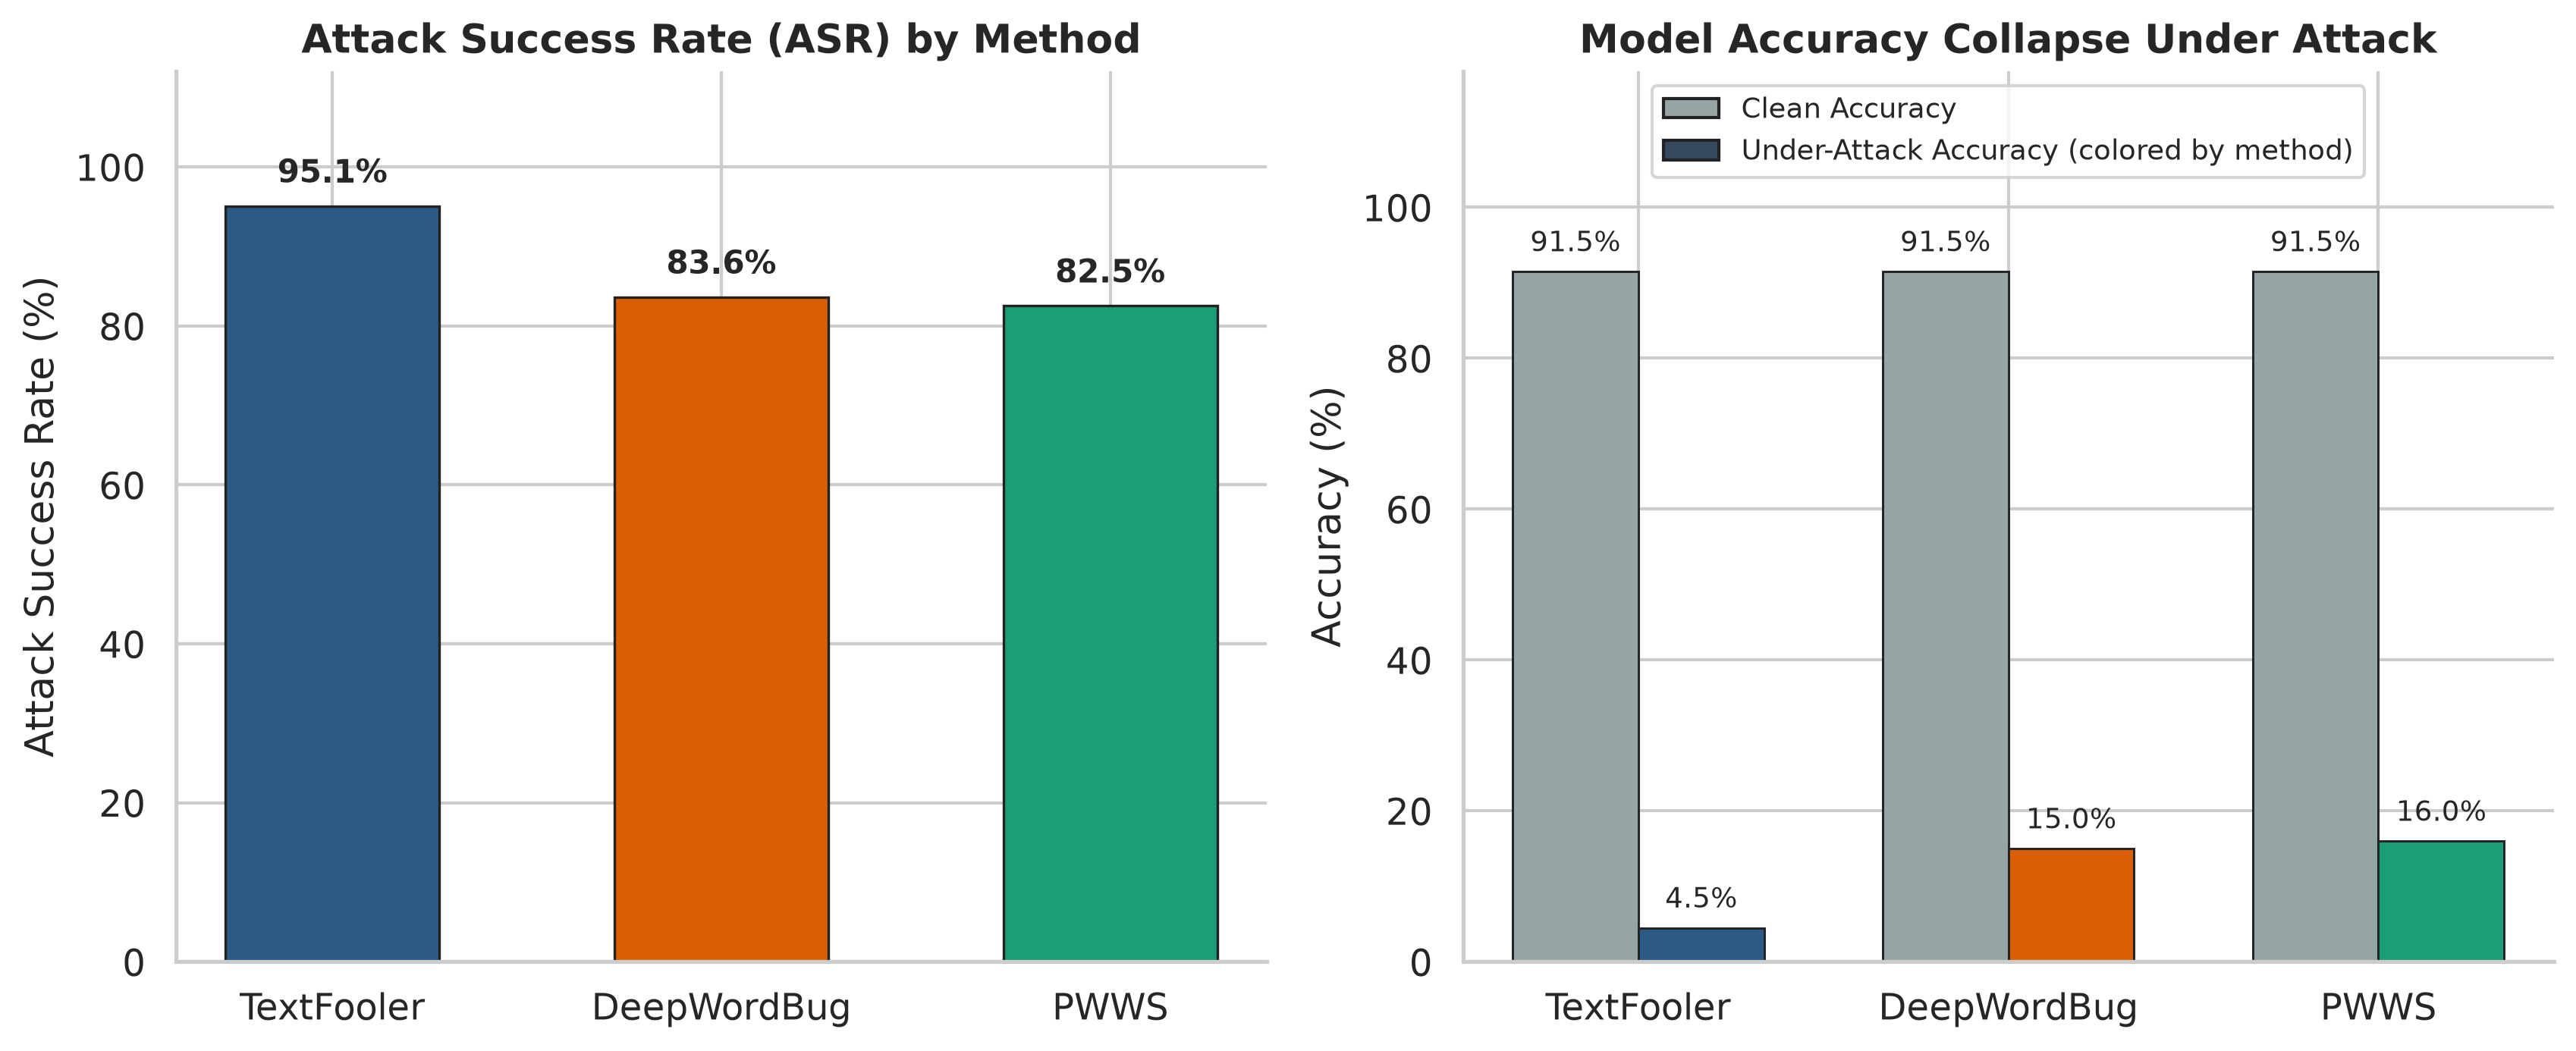

[SAVED] outputs/figures/01_success_rate_by_attack.png


In [16]:
METHOD_ORDER = list(CFG["attacks"]["recipes"])
METHOD_LABELS = {"textfooler": "TextFooler", "deepwordbug": "DeepWordBug", "pwws": "PWWS"}
METHOD_COLORS = {m: PALETTE.get(m, "#4C72B0") for m in METHOD_ORDER}

# Safe fallback if you restarted the kernel and jumped straight to Section 6
if "df_baseline_summary" not in globals():
    df_baseline_summary = pd.read_csv(DIRS["csv_dir"] / "baseline_attack_summary.csv")

# ---------------------------------------------------------------------------
# Plot 1: Attack Success Rate by Attack Method (300 DPI PNG)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=DPI)

plot_df = df_baseline_summary.set_index("attack_method").loc[METHOD_ORDER].reset_index()
x_labels = [METHOD_LABELS[m] for m in plot_df["attack_method"]]
bar_colors = [METHOD_COLORS[m] for m in plot_df["attack_method"]]

# Left panel: Attack Success Rate (%)
bars = axes[0].bar(
    x_labels,
    plot_df["attack_success_rate_pct"],
    color=bar_colors,
    width=0.55,
    edgecolor="#222222",
    linewidth=0.8,
)
axes[0].set_ylim(0, 112)
axes[0].set_ylabel("Attack Success Rate (%)")
axes[0].set_title("Attack Success Rate (ASR) by Method", fontweight="bold")
for bar, val in zip(bars, plot_df["attack_success_rate_pct"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + 2.0,
        f"{val:.1f}%",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=10,
    )

# Right panel: Clean vs. Under-Attack Accuracy (%)
x = np.arange(len(x_labels))
w = 0.34
b1 = axes[1].bar(
    x - w / 2,
    plot_df["original_accuracy_pct"],
    width=w,
    color="#95A5A6",
    edgecolor="#222222",
    linewidth=0.7,
)
b2 = axes[1].bar(
    x + w / 2,
    plot_df["under_attack_accuracy_pct"],
    width=w,
    color=bar_colors,
    edgecolor="#222222",
    linewidth=0.7,
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(x_labels)
axes[1].set_ylim(0, 118)
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Model Accuracy Collapse Under Attack", fontweight="bold")

legend_handles = [
    patches.Patch(facecolor="#95A5A6", edgecolor="#222222", label="Clean Accuracy"),
    patches.Patch(facecolor="#34495E", edgecolor="#222222", label="Under-Attack Accuracy (colored by method)"),
]
axes[1].legend(handles=legend_handles, frameon=True, loc="upper center", ncol=1, fontsize=8.8)

for bar in list(b1) + list(b2):
    val = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        val + 1.8,
        f"{val:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8.8,
    )

sns.despine(fig=fig)
plt.tight_layout()
p1 = DIRS["figures_dir"] / "01_success_rate_by_attack.png"
fig.savefig(p1, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()
print(f"[SAVED] {p1}")

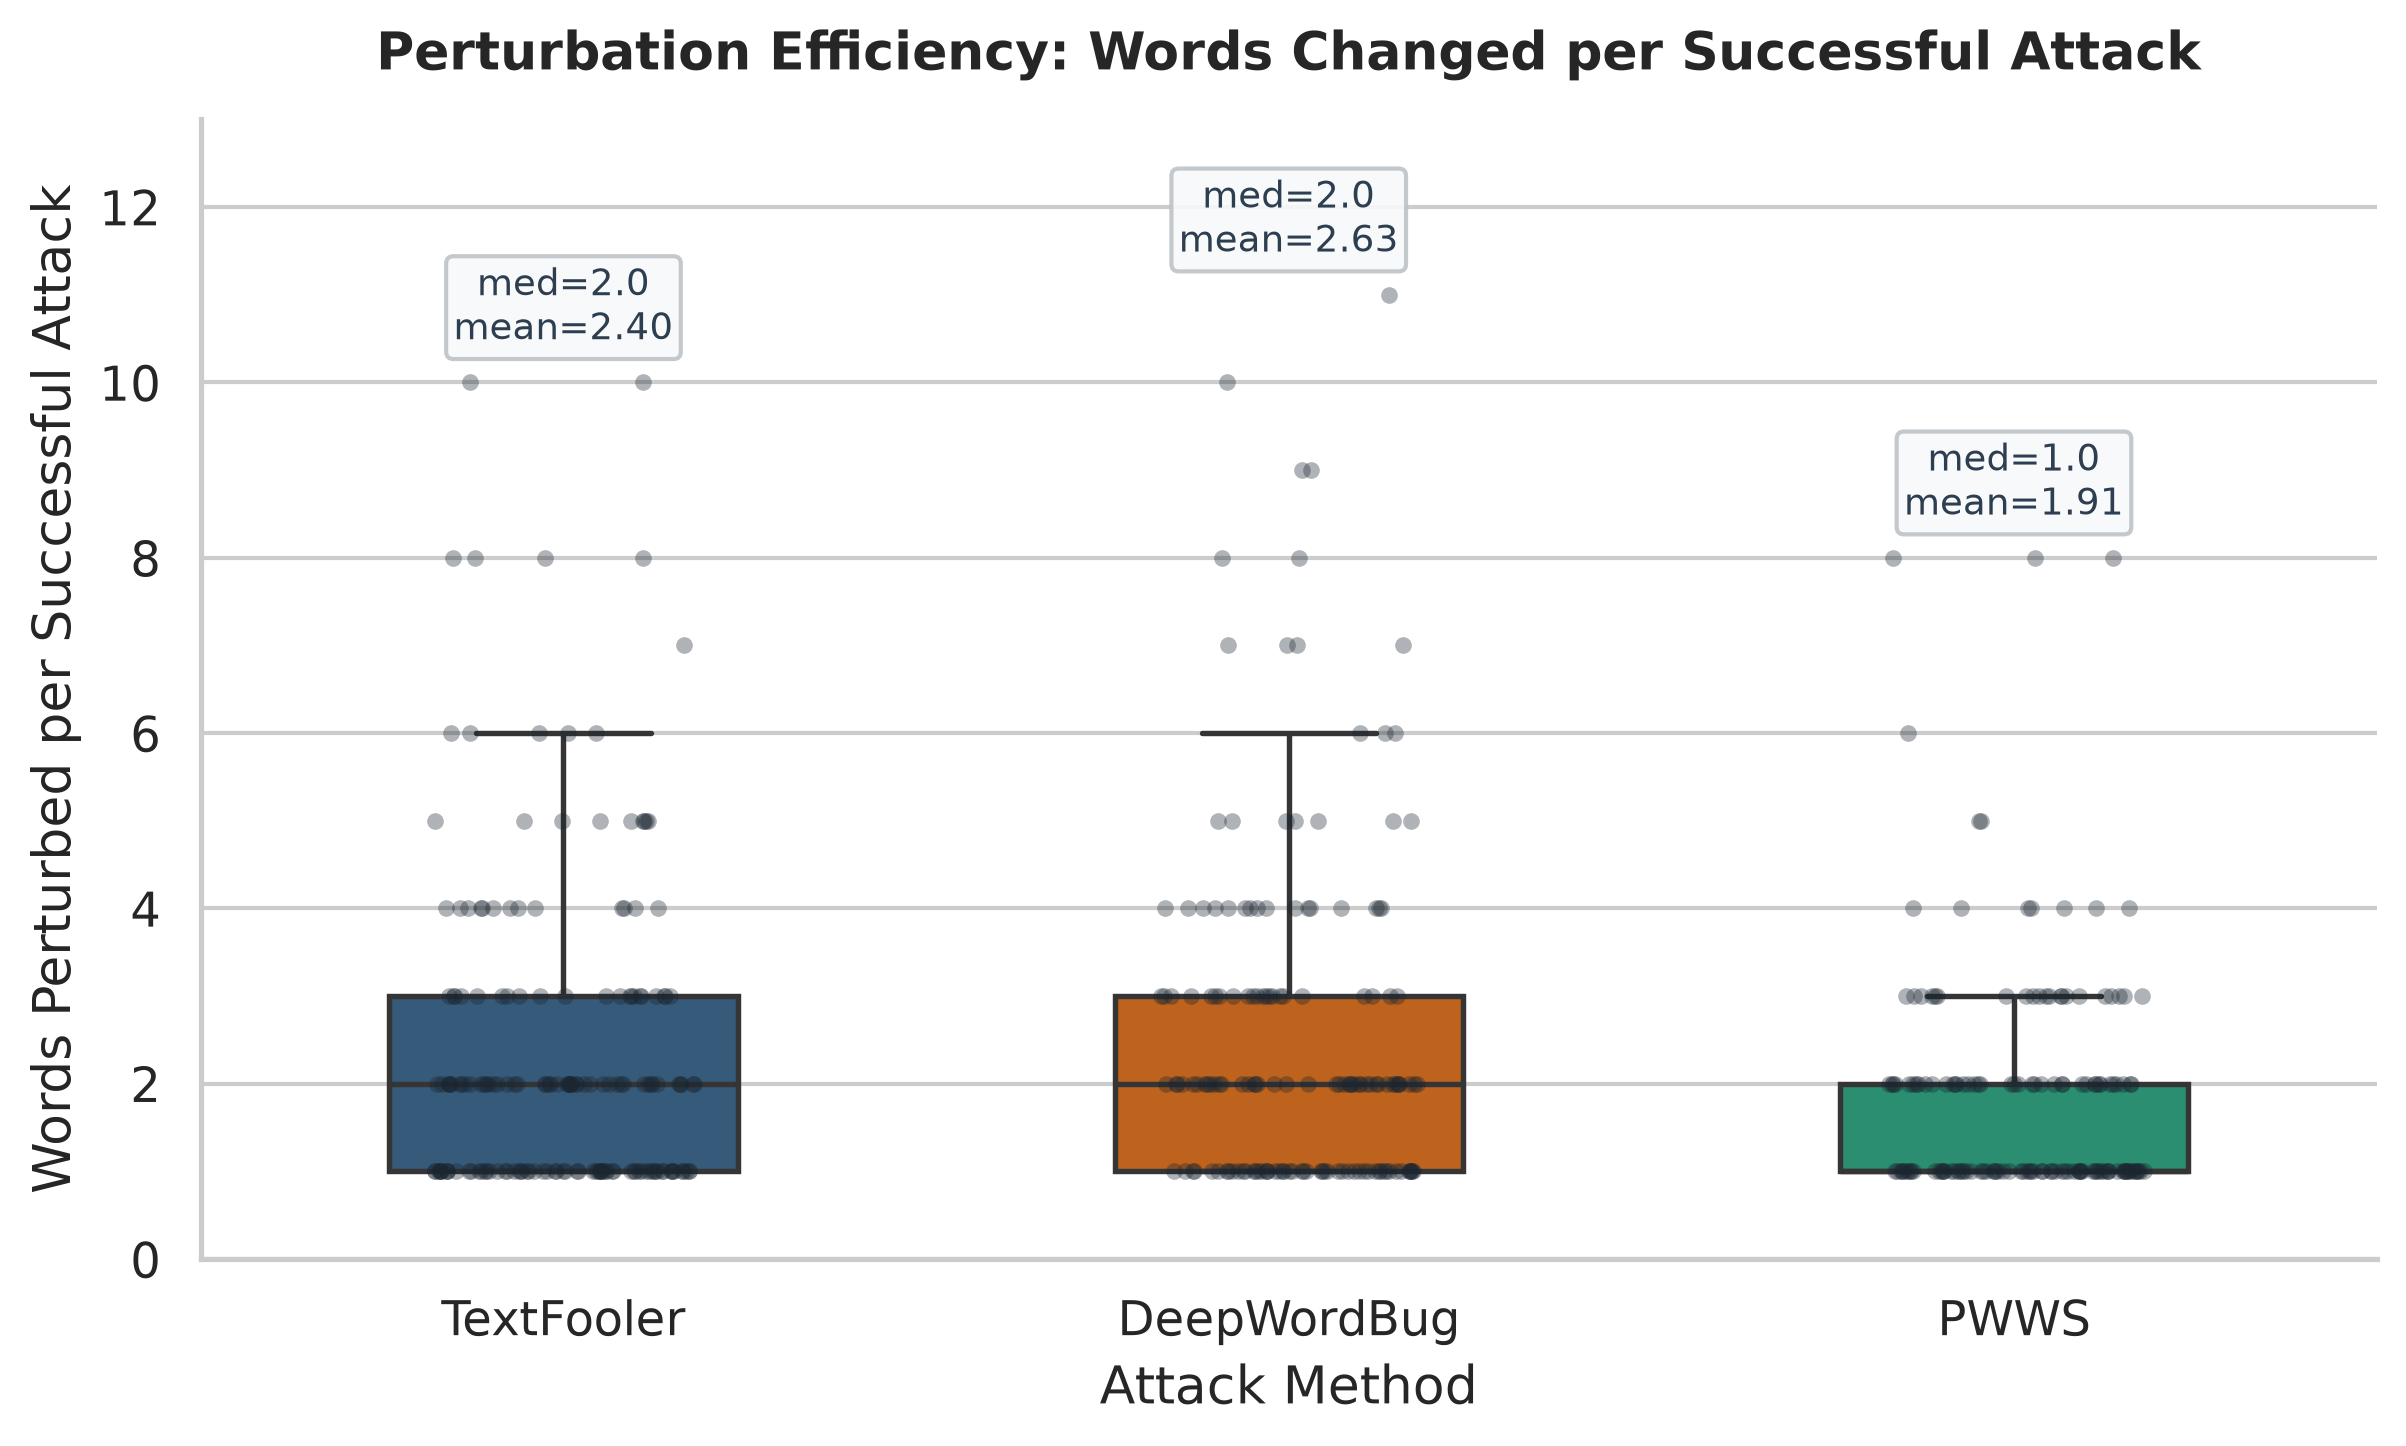

[SAVED] outputs/figures/02_words_perturbed_boxplot.png


In [17]:
# ---------------------------------------------------------------------------
# Plot 2: Words Perturbed Box Plot (300 DPI PNG)
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.2, 5.0), dpi=DPI)
df_succ_plot = df_baseline_successful.copy()
df_succ_plot["method_label"] = df_succ_plot["attack_method"].map(METHOD_LABELS)
order_labels = [METHOD_LABELS[m] for m in METHOD_ORDER]
palette_labels = {METHOD_LABELS[m]: METHOD_COLORS[m] for m in METHOD_ORDER}

sns.boxplot(
    data=df_succ_plot,
    x="method_label",
    y="words_changed",
    order=order_labels,
    hue="method_label",
    palette=palette_labels,
    dodge=False,
    width=0.48,
    showfliers=False,
    linewidth=1.3,
    ax=ax,
)
if ax.get_legend() is not None:
    ax.get_legend().remove()

sns.stripplot(
    data=df_succ_plot,
    x="method_label",
    y="words_changed",
    order=order_labels,
    color="#1B2631",
    alpha=0.35,
    size=4,
    jitter=0.18,
    ax=ax,
)

for idx, m in enumerate(METHOD_ORDER):
    sub = df_baseline_successful[df_baseline_successful["attack_method"] == m]["words_changed"]
    if len(sub):
        ax.text(
            idx, sub.max() + 0.35,
            f"med={sub.median():.1f}\nmean={sub.mean():.2f}",
            ha="center", va="bottom", fontsize=8.8, color="#2C3E50",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="#F8F9FA", edgecolor="#BDC3C7", alpha=0.9),
        )

ax.set_xlabel("Attack Method")
ax.set_ylabel("Words Perturbed per Successful Attack")
ax.set_title("Perturbation Efficiency: Words Changed per Successful Attack", fontweight="bold", pad=12)
ax.set_ylim(bottom=0, top=max(df_succ_plot["words_changed"].max() + 2.0, 5))
sns.despine(ax=ax)
plt.tight_layout()
p2 = DIRS["figures_dir"] / "02_words_perturbed_boxplot.png"
fig.savefig(p2, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()
print(f"[SAVED] {p2}")


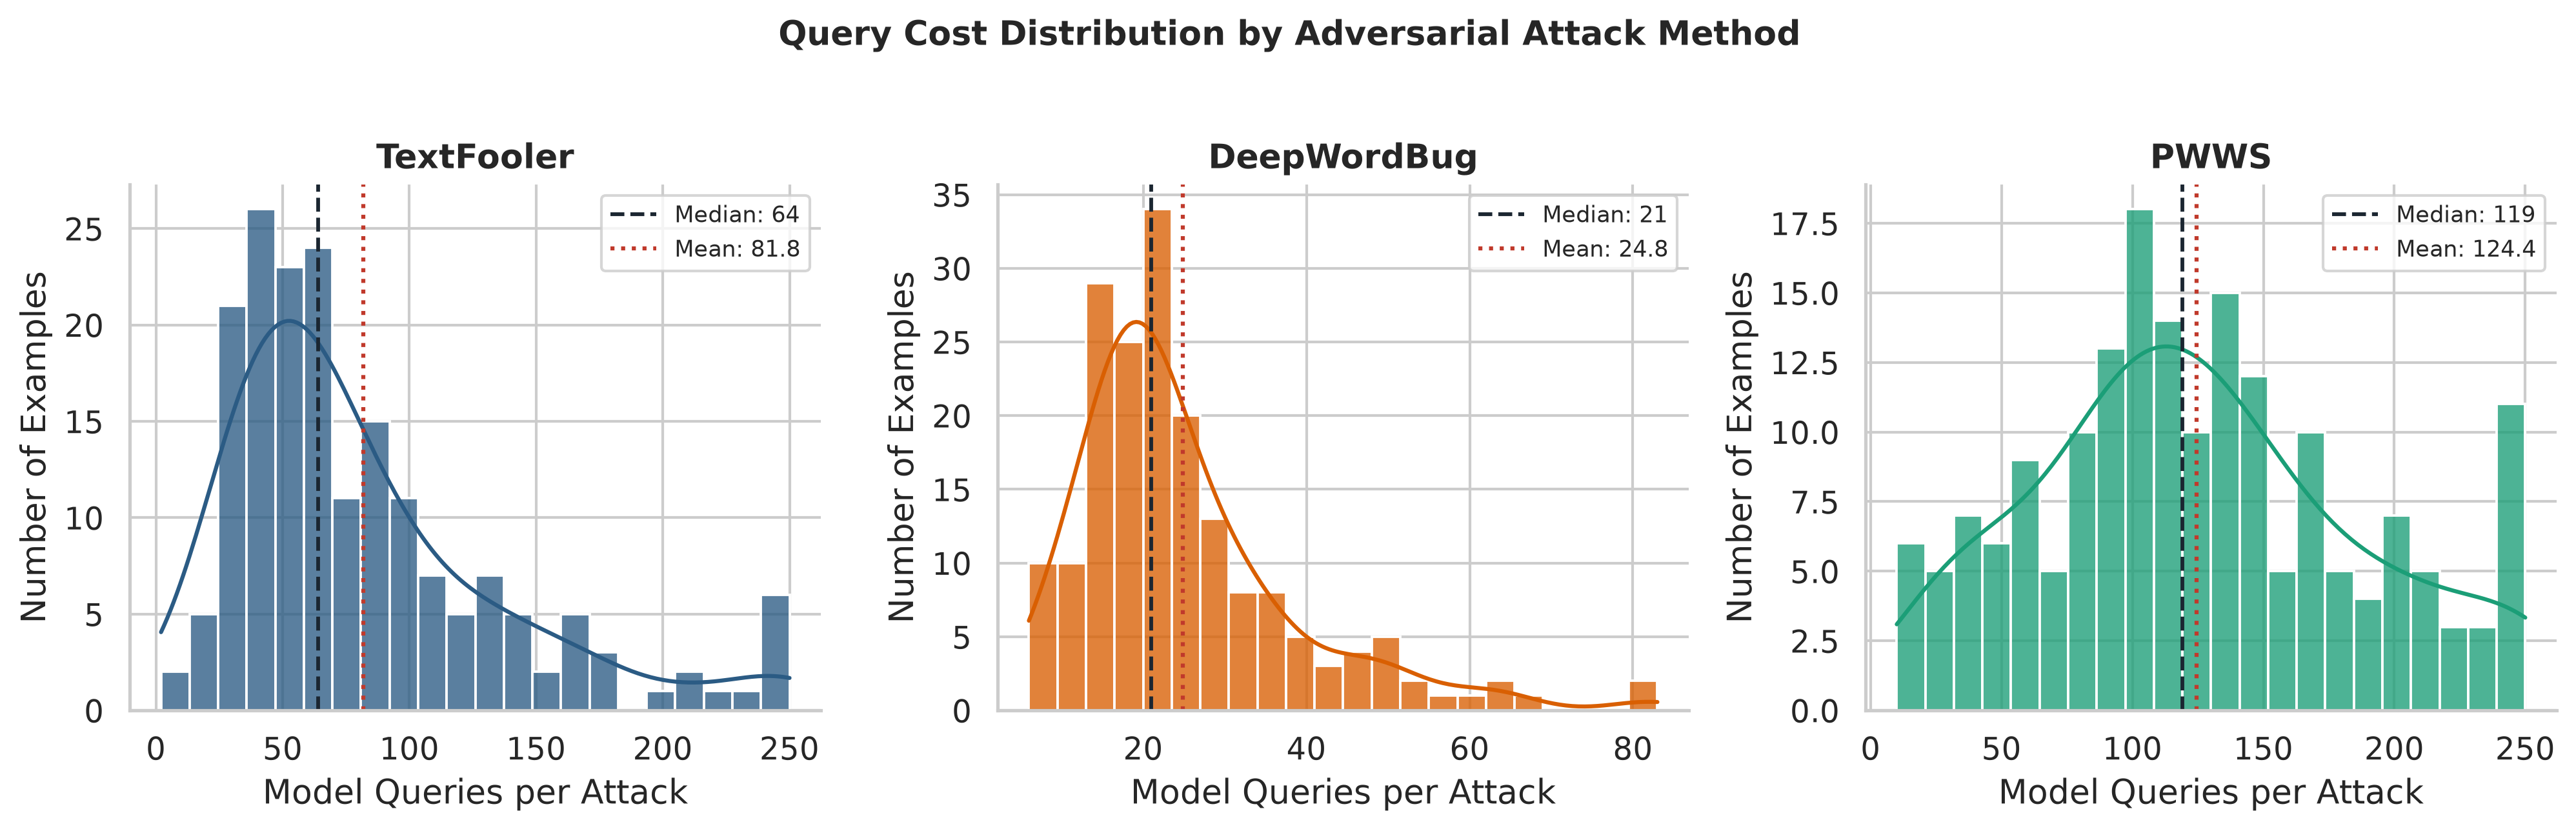

[SAVED] outputs/figures/03_query_count_histogram.png


In [18]:
# ---------------------------------------------------------------------------
# Plot 3: Query Count Histogram per Attack (300 DPI PNG)
# ---------------------------------------------------------------------------
df_non_skipped = df_baseline_attacks[df_baseline_attacks["status"] != "Skipped"].copy()
fig, axes = plt.subplots(1, len(METHOD_ORDER), figsize=(13.5, 4.2), dpi=DPI, sharey=False)
if len(METHOD_ORDER) == 1:
    axes = [axes]

for ax, m in zip(axes, METHOD_ORDER):
    sub = df_non_skipped[df_non_skipped["attack_method"] == m]["num_queries"]
    sns.histplot(sub, bins=22, kde=True, color=METHOD_COLORS[m], edgecolor="white", alpha=0.78, ax=ax)
    if len(sub):
        med = sub.median()
        mean = sub.mean()
        ax.axvline(med, color="#1B2631", linestyle="--", linewidth=1.4, label=f"Median: {med:.0f}")
        ax.axvline(mean, color="#C0392B", linestyle=":", linewidth=1.5, label=f"Mean: {mean:.1f}")
        ax.legend(frameon=True, fontsize=8.5)
    ax.set_title(f"{METHOD_LABELS[m]}", fontweight="bold")
    ax.set_xlabel("Model Queries per Attack")
    ax.set_ylabel("Number of Examples")
    sns.despine(ax=ax)

fig.suptitle("Query Cost Distribution by Adversarial Attack Method", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
p3 = DIRS["figures_dir"] / "03_query_count_histogram.png"
fig.savefig(p3, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()
print(f"[SAVED] {p3}")


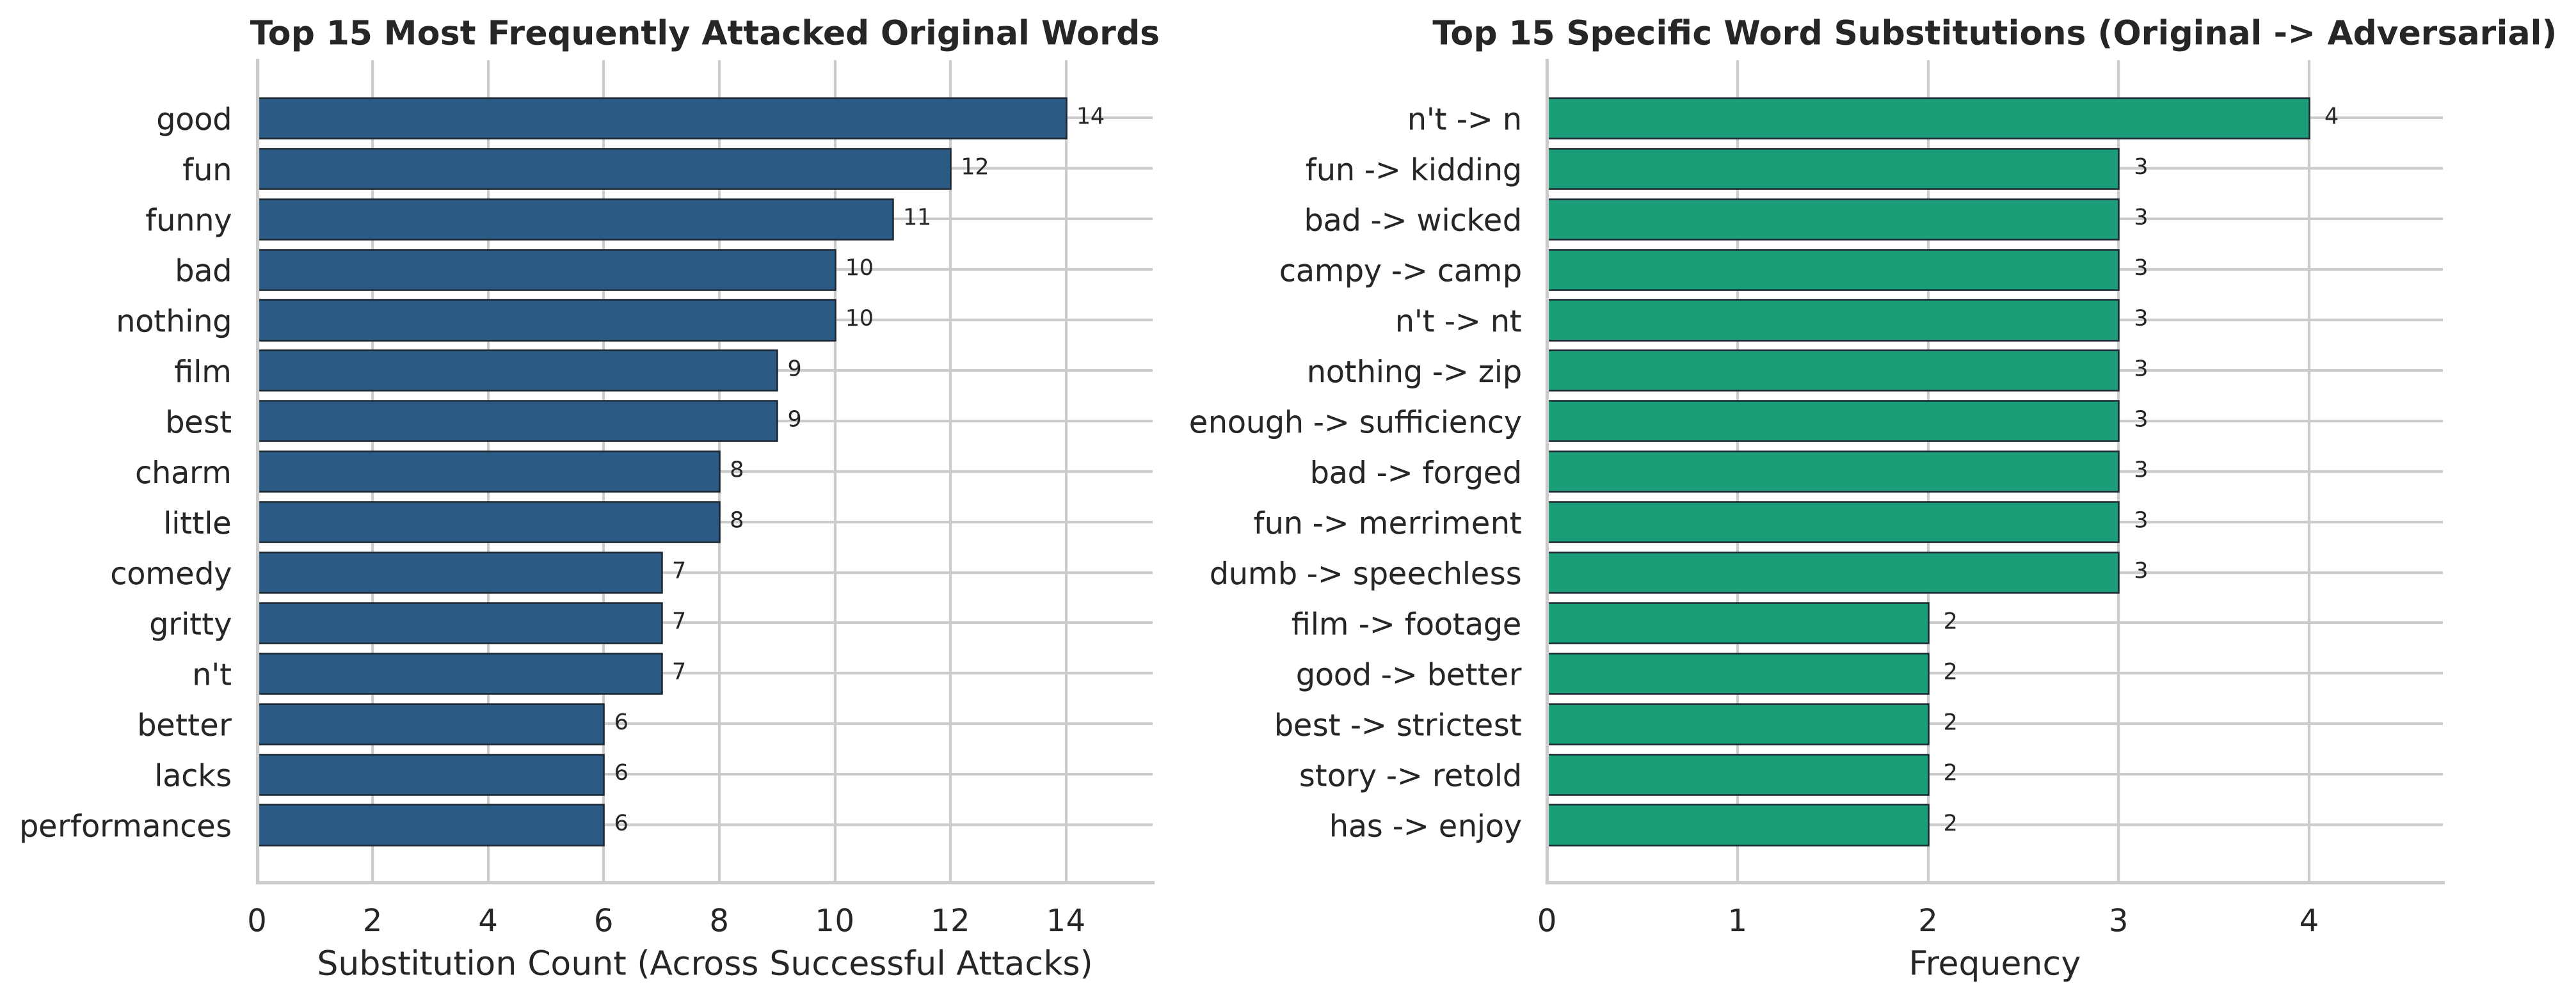

[SAVED] outputs/figures/05_most_substituted_words.png


In [19]:
# ---------------------------------------------------------------------------
# Plot 5: Most Frequently Substituted Words Bar Chart (300 DPI PNG)
# (Plot 4 token attribution heatmaps were exported in Section 4)
# ---------------------------------------------------------------------------
from matplotlib.ticker import MaxNLocator

# ---------------------------------------------------------------------------
# Plot 5: Most Frequently Substituted Words Bar Chart (300 DPI PNG)
# ---------------------------------------------------------------------------
orig_word_counter = Counter()
pair_counter = Counter()

for raw_subs in df_baseline_successful["word_substitutions"].dropna():
    try:
        pairs_list = json.loads(raw_subs)
    except Exception:
        continue
    for ow, aw in pairs_list:
        ow_c = ow.lower().strip(".,!?;:'\"")
        aw_c = aw.lower().strip(".,!?;:'\"")
        if len(ow_c) > 1:
            orig_word_counter[ow_c] += 1
            pair_counter[f"{ow_c} -> {aw_c}"] += 1

top_k = int(CFG["visualization"]["top_k_substituted_words"])
top_words = orig_word_counter.most_common(top_k)
top_pairs = pair_counter.most_common(top_k)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4), dpi=DPI)

if top_words:
    words_x, words_y = zip(*reversed(top_words))
    axes[0].barh(words_x, words_y, color="#2B5B84", edgecolor="#1B2631", linewidth=0.6)
    for i, v in enumerate(words_y):
        axes[0].text(v + 0.18, i, str(v), va="center", fontsize=8.5)
    axes[0].set_xlim(0, max(words_y) + 1.5)
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_title(f"Top {top_k} Most Frequently Attacked Original Words", fontweight="bold")
axes[0].set_xlabel("Substitution Count (Across Successful Attacks)")

if top_pairs:
    pairs_x, pairs_y = zip(*reversed(top_pairs))
    axes[1].barh(pairs_x, pairs_y, color="#1B9E77", edgecolor="#1B2631", linewidth=0.6)
    for i, v in enumerate(pairs_y):
        axes[1].text(v + 0.08, i, str(v), va="center", fontsize=8.5)
    axes[1].set_xlim(0, max(pairs_y) + 0.7)
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].set_title(f"Top {top_k} Specific Word Substitutions (Original -> Adversarial)", fontweight="bold")
axes[1].set_xlabel("Frequency")

sns.despine(fig=fig)
plt.tight_layout()
p5 = DIRS["figures_dir"] / "05_most_substituted_words.png"
fig.savefig(p5, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()
print(f"[SAVED] {p5}")

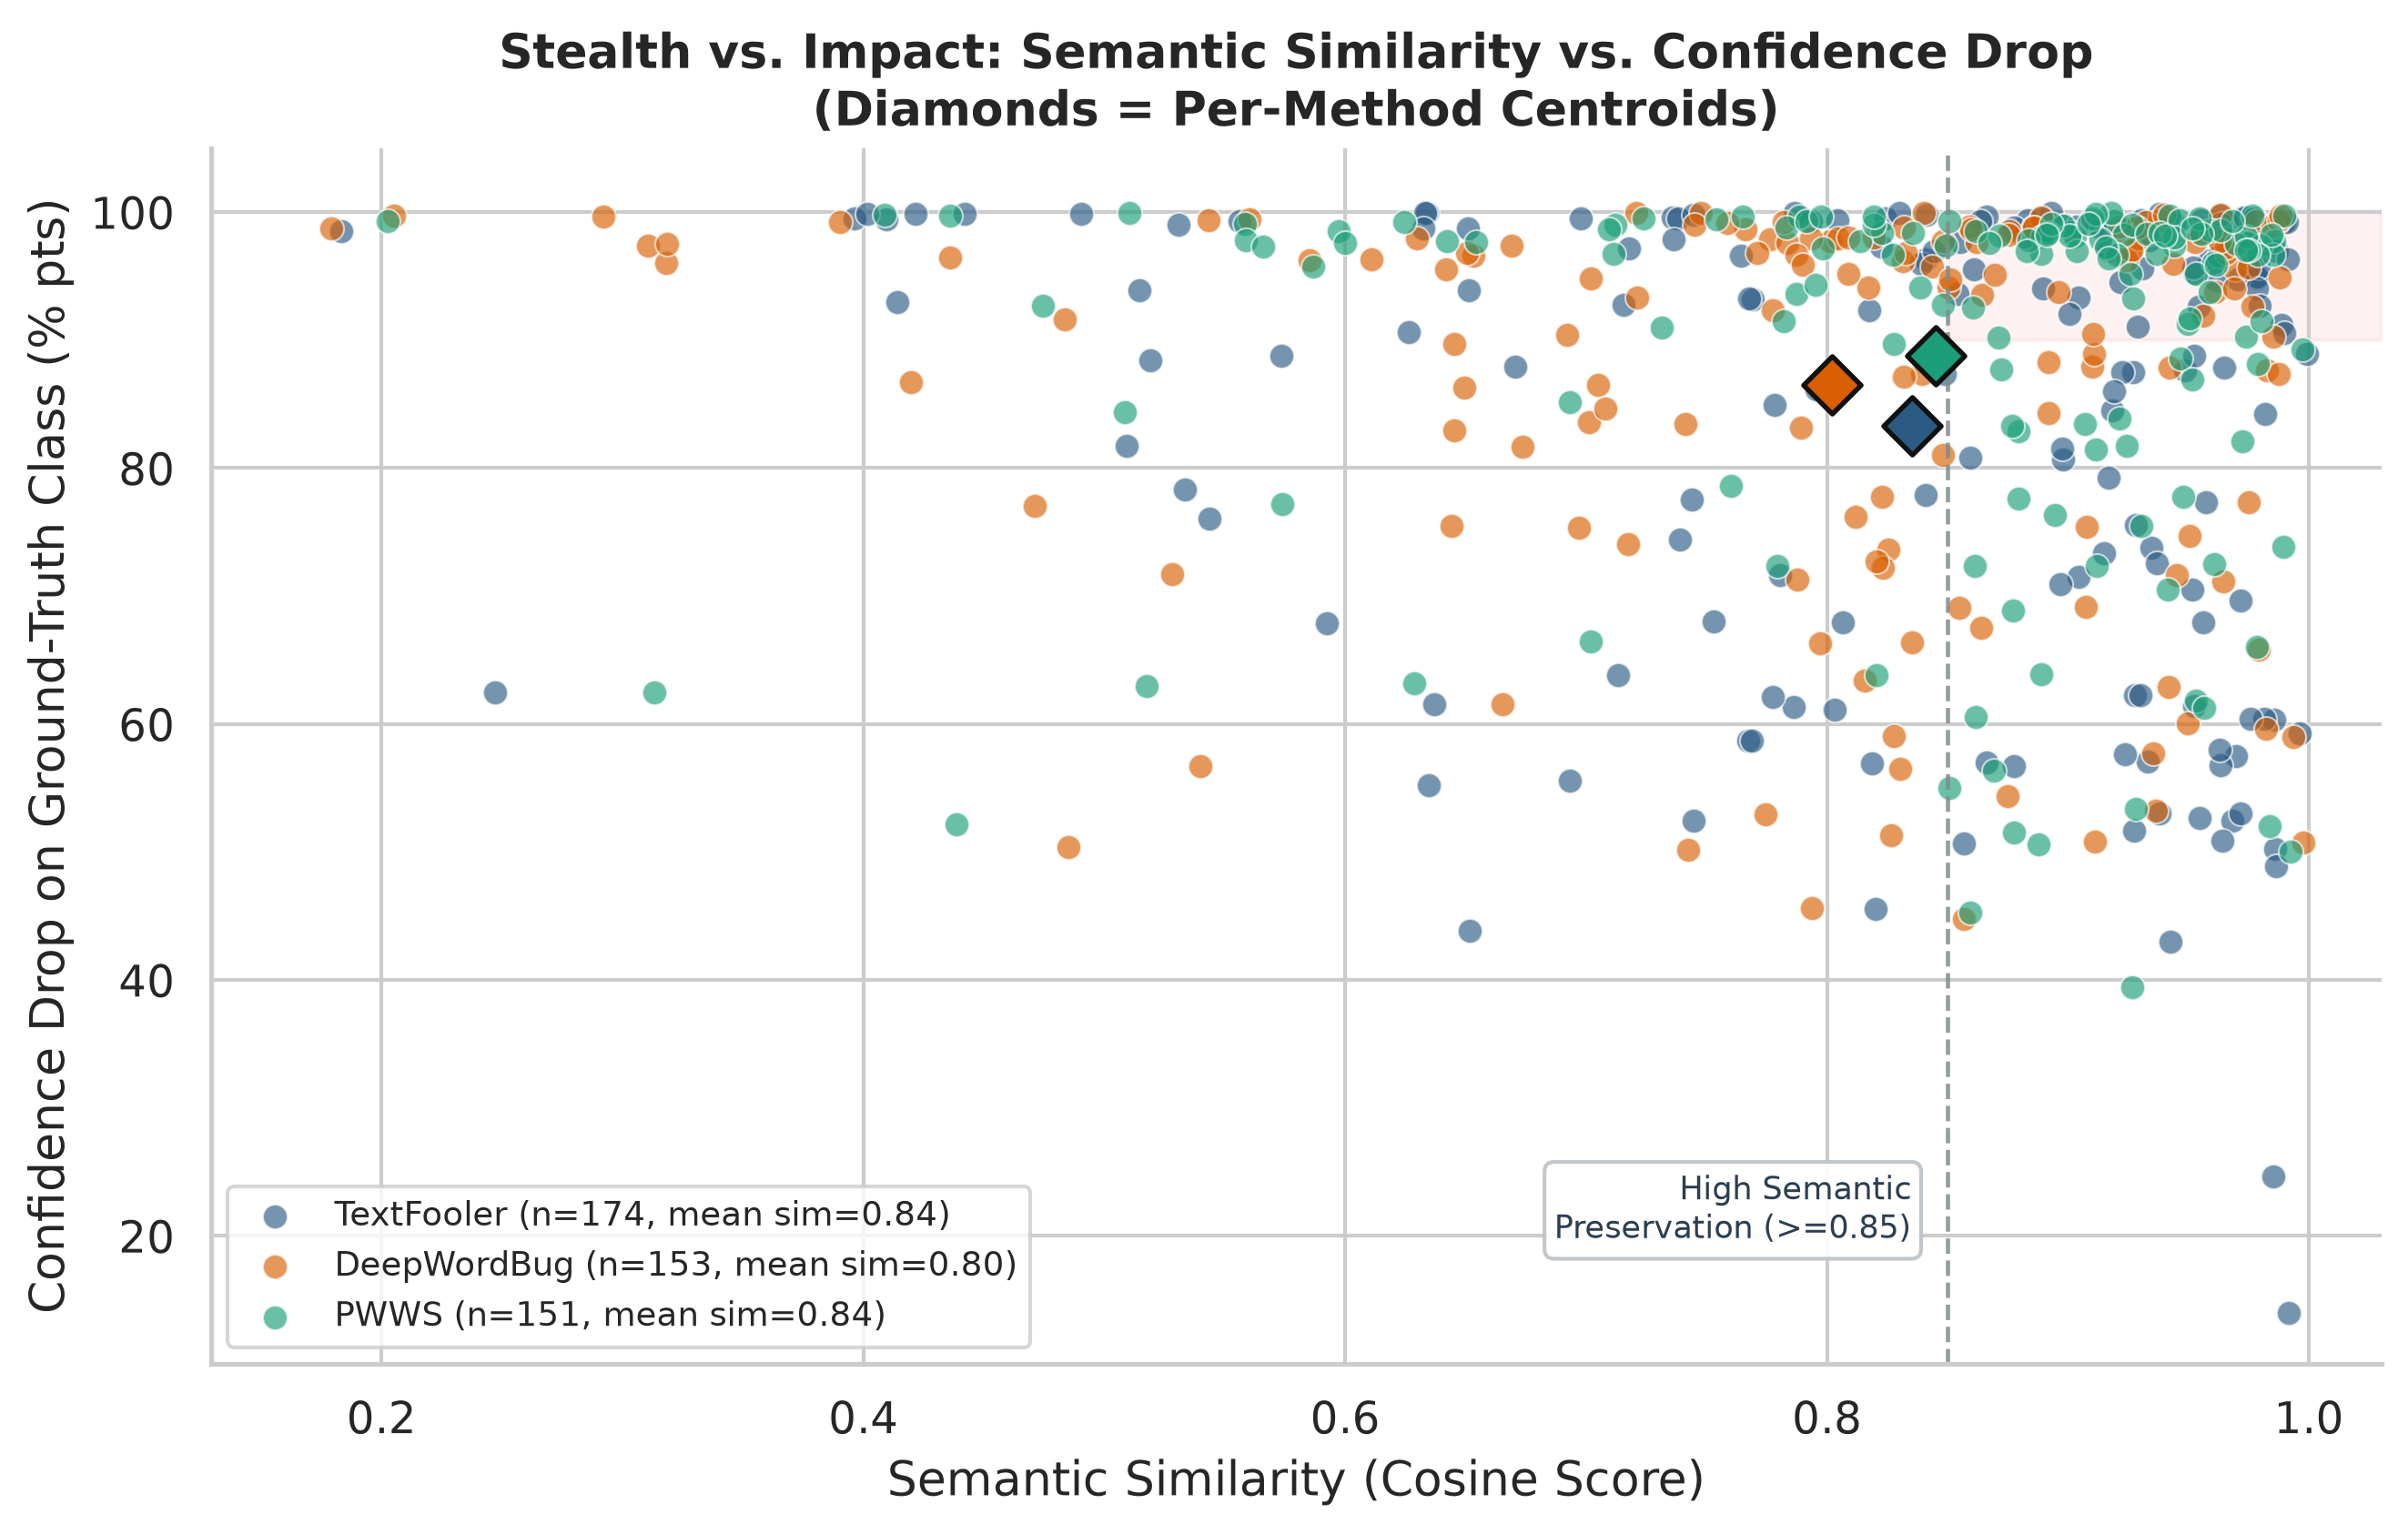

[SAVED] outputs/figures/06_similarity_vs_confidence_drop.png


In [20]:
# ---------------------------------------------------------------------------
# Plot 6: Semantic Similarity vs. Confidence Drop Scatter (300 DPI PNG)
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.0, 5.8), dpi=DPI)
y_min, y_max = 10, 105

# Subtle highlight for the Stealth + Lethal quadrant (sim >= 0.85, conf_drop >= 90%)
ax.axvspan(
    0.85, 1.03,
    ymin=(90 - y_min) / (y_max - y_min),
    ymax=(100 - y_min) / (y_max - y_min),
    color="#E74C3C", alpha=0.07, zorder=0,
)

for m in METHOD_ORDER:
    sub = df_baseline_successful[df_baseline_successful["attack_method"] == m]
    if len(sub) == 0:
        continue
    ax.scatter(
        sub["semantic_similarity"],
        sub["confidence_drop"] * 100.0,
        label=f"{METHOD_LABELS[m]} (n={len(sub)}, mean sim={sub['semantic_similarity'].mean():.2f})",
        color=METHOD_COLORS[m],
        alpha=0.65,
        s=42,
        edgecolors="white",
        linewidth=0.5,
    )
    ax.scatter(
        sub["semantic_similarity"].mean(),
        sub["confidence_drop"].mean() * 100.0,
        color=METHOD_COLORS[m],
        marker="D",
        s=115,
        edgecolors="#111111",
        linewidth=1.3,
        zorder=5,
    )

ax.axvline(0.85, color="#7F8C8D", linestyle="--", linewidth=1.1, alpha=0.85)
ax.text(
    0.835, 22, "High Semantic\nPreservation (>=0.85)",
    fontsize=8.5, color="#2C3E50", ha="right", va="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#BDC3C7", alpha=0.92),
)

ax.set_xlabel("Semantic Similarity (Cosine Score)")
ax.set_ylabel("Confidence Drop on Ground-Truth Class (% pts)")
ax.set_title(
    "Stealth vs. Impact: Semantic Similarity vs. Confidence Drop\n(Diamonds = Per-Method Centroids)",
    fontweight="bold",
)
ax.set_xlim(max(0.0, df_baseline_successful["semantic_similarity"].min() - 0.05), 1.03)
ax.set_ylim(y_min, y_max)
ax.legend(frameon=True, loc="lower left", fontsize=8.8)
sns.despine(ax=ax)
plt.tight_layout()
p6 = DIRS["figures_dir"] / "06_similarity_vs_confidence_drop.png"
fig.savefig(p6, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()
print(f"[SAVED] {p6}")

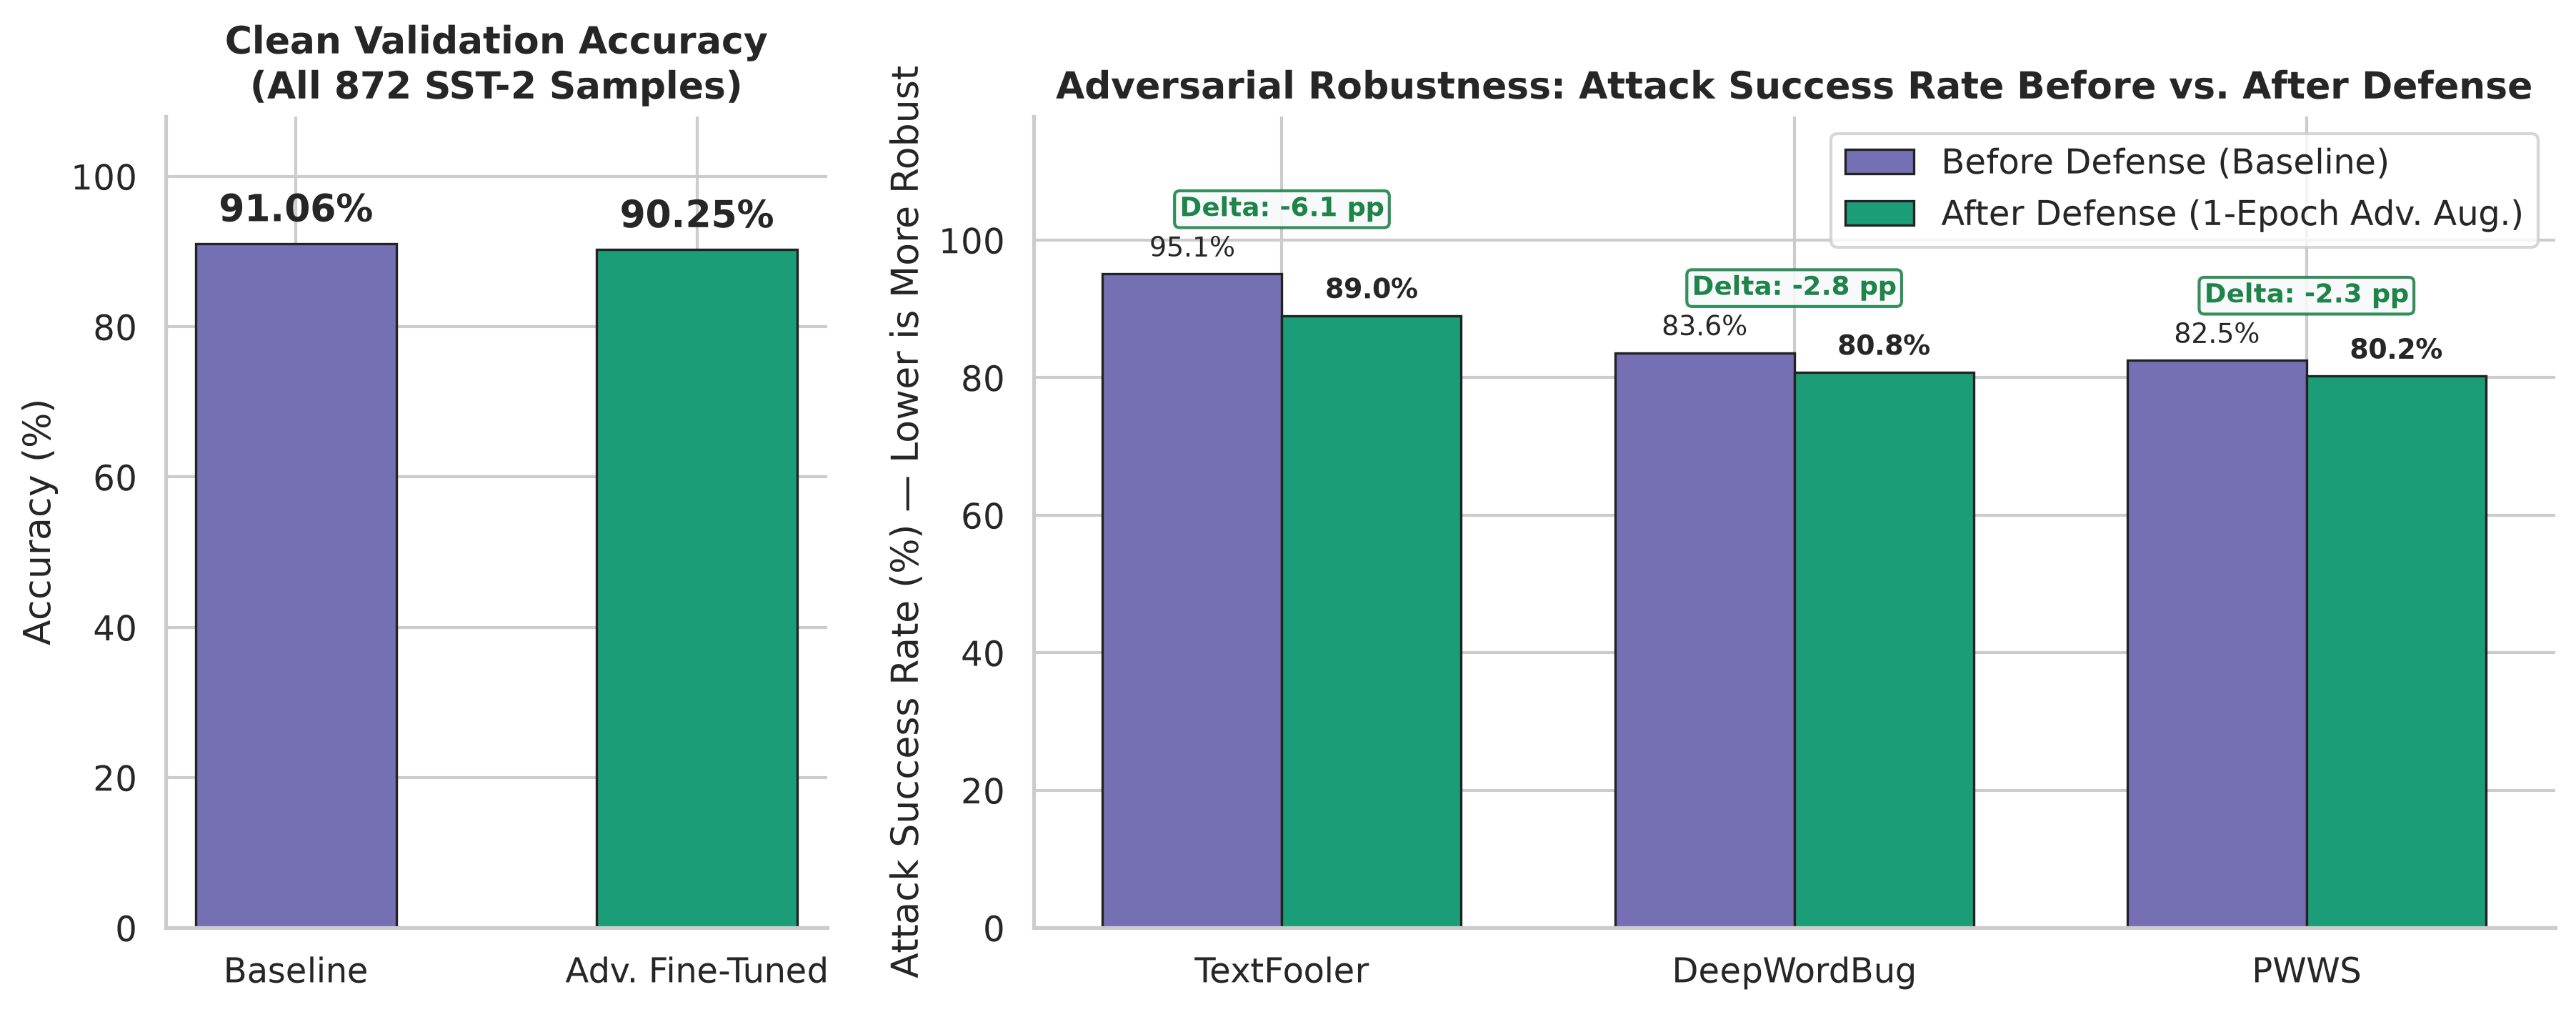

[SAVED] outputs/figures/07_before_after_defense_comparison.png


In [21]:
# ---------------------------------------------------------------------------
# Plot 7: Before vs. After Defense Comparison (300 DPI PNG)
# ---------------------------------------------------------------------------
if CFG["defense"].get("enabled", True):
    fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.9), dpi=DPI, gridspec_kw={"width_ratios": [1.0, 2.3]})

    clean_vals = [
        baseline_clean_metrics["clean_accuracy"] * 100.0,
        defended_clean_metrics["clean_accuracy"] * 100.0,
    ]
    c_bars = axes[0].bar(
        ["Baseline", "Adv. Fine-Tuned"],
        clean_vals,
        color=[PALETTE["before"], PALETTE["after"]],
        width=0.5,
        edgecolor="#222222",
        linewidth=0.8,
    )
    axes[0].set_ylim(0, 108)
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title("Clean Validation Accuracy\n(All 872 SST-2 Samples)", fontweight="bold")
    for b, v in zip(c_bars, clean_vals):
        axes[0].text(b.get_x() + b.get_width() / 2, v + 1.8, f"{v:.2f}%", ha="center", va="bottom", fontweight="bold")

    comp = df_comparison.set_index("attack_method").loc[METHOD_ORDER].reset_index()
    x = np.arange(len(METHOD_ORDER))
    w = 0.35

    axes[1].bar(
        x - w / 2, comp["attack_success_rate_pct_before"], width=w,
        label="Before Defense (Baseline)", color=PALETTE["before"], edgecolor="#222222", linewidth=0.8,
    )
    axes[1].bar(
        x + w / 2, comp["attack_success_rate_pct_after"], width=w,
        label="After Defense (1-Epoch Adv. Aug.)", color=PALETTE["after"], edgecolor="#222222", linewidth=0.8,
    )

    for i, (vb, va, delta) in enumerate(zip(
        comp["attack_success_rate_pct_before"],
        comp["attack_success_rate_pct_after"],
        comp["asr_delta_pp"],
    )):
        axes[1].text(x[i] - w / 2, vb + 1.6, f"{vb:.1f}%", ha="center", va="bottom", fontsize=9)
        axes[1].text(x[i] + w / 2, va + 1.6, f"{va:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
        sign = "+" if delta > 0 else ""
        delta_color = "#1E8449" if delta < 0 else "#C0392B"
        axes[1].text(
            x[i], max(vb, va) + 7.5, f"Delta: {sign}{delta:.1f} pp",
            ha="center", va="bottom", fontsize=8.8, fontweight="bold", color=delta_color,
            bbox=dict(boxstyle="round,pad=0.2", facecolor="#F8F9FA", edgecolor=delta_color, alpha=0.9),
        )

    axes[1].set_xticks(x)
    axes[1].set_xticklabels([METHOD_LABELS[m] for m in METHOD_ORDER])
    axes[1].set_ylim(0, 118)
    axes[1].set_ylabel("Attack Success Rate (%) — Lower is More Robust")
    axes[1].set_title("Adversarial Robustness: Attack Success Rate Before vs. After Defense", fontweight="bold")
    axes[1].legend(frameon=True, loc="upper right")

    sns.despine(fig=fig)
    plt.tight_layout()
    p7 = DIRS["figures_dir"] / "07_before_after_defense_comparison.png"
    fig.savefig(p7, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"[SAVED] {p7}")


---
## Section 7: Runtime Summary & Portfolio Artifact Checklist

Confirm total CPU runtime (target: < 10 hours) and verify every CSV, HTML, model checkpoint, and 300 DPI PNG artifact was generated.


In [22]:
total_sec = sum(SECTION_TIMINGS.values())
timing_df = pd.DataFrame([
    {"section": k, "seconds": round(v, 1), "minutes": round(v / 60.0, 2)}
    for k, v in SECTION_TIMINGS.items()
])
display(timing_df)
print(f"\nTotal Notebook Runtime: {total_sec / 60.0:.2f} minutes ({total_sec / 3600.0:.2f} hours)")

print("\nGenerated Artifacts:")
for folder_key in ["csv_dir", "figures_dir", "html_dir", "models_dir"]:
    folder = DIRS[folder_key]
    files = sorted(folder.glob("*"))
    print(f"  [{folder}] ({len(files)} items)")
    for fp in files:
        size_kb = fp.stat().st_size / 1024.0 if fp.is_file() else 0.0
        tag = f"{size_kb:,.1f} KB" if fp.is_file() else "DIR"
        print(f"    - {fp.name} ({tag})")


,section,seconds,minutes
0,Section 1: Data & Model Loading,6.0,0.10
1,Section 1: Clean Baseline Evaluation,23.8,0.40
2,Section 2: Load Semantic Similarity Scorer,0.9,0.02
3,Section 2: Smoke Test (TextFooler on 15 samples),0.0,0.00
4,Attack [baseline] -> textfooler,0.0,0.00
5,Attack [baseline] -> deepwordbug,0.0,0.00
6,Attack [baseline] -> pwws,0.0,0.00
7,"Section 2: Baseline Attack Suite (TextFooler, DeepWordBug, PWWS)",0.0,0.00
8,Section 4: Captum Integrated Gradients on Clean & Adversarial Pairs,0.0,0.00
9,Section 5a: Generate Adversarial Training Examples,0.0,0.00



Total Notebook Runtime: 3.97 minutes (0.07 hours)

Generated Artifacts:
  [outputs/csv] (21 items)
    - baseline_attack_results_detailed.csv (269.2 KB)
    - baseline_attack_summary.csv (0.6 KB)
    - baseline_clean_metrics.json (0.3 KB)
    - baseline_clean_predictions.csv (140.7 KB)
    - baseline_deepwordbug_detailed.csv (92.1 KB)
    - baseline_pwws_detailed.csv (87.4 KB)
    - baseline_successful_pairs.csv (219.9 KB)
    - baseline_textfooler_detailed.csv (90.2 KB)
    - defended_attack_results_detailed.csv (274.8 KB)
    - defended_attack_summary.csv (0.6 KB)
    - defended_clean_metrics.json (0.3 KB)
    - defended_clean_predictions.csv (139.4 KB)
    - defended_deepwordbug_detailed.csv (95.4 KB)
    - defended_pwws_detailed.csv (88.3 KB)
    - defended_successful_pairs.csv (212.0 KB)
    - defended_textfooler_detailed.csv (91.7 KB)
    - defense_adv_train_examples.csv (37.7 KB)
    - defense_before_after_comparison.csv (0.5 KB)
    - ig_attributions_summary.csv (4.4 KB)
    -